# Location Analyzer v2 - Machine Learning Pipeline

## 1. Setup & Data Loading
We will analyze `v3_master_combined.csv` which contains both Historical and Prediction data.

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Pandas display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Define file path
DATA_PATH = r"D:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\data\processed\v3_master_combined.csv"

print(f"Loading data from: {DATA_PATH}")

Loading data from: D:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\data\processed\v3_master_combined.csv


In [48]:
# Load the dataset
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
    print("Data loaded successfully!")
    print(f"Shape: {df.shape}")
except Exception as e:
    print(f"Error loading data: {e}")

Data loaded successfully!
Shape: (91701, 25)


## 2. In-Depth Data Analysis (EDA)
### 2.1 Structure & Types

In [49]:
# Check column types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 91701 entries, 0 to 91700
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Day_of_Week                    91701 non-null  str    
 1   Date                           91701 non-null  str    
 2   Branch Name                    91701 non-null  str    
 3   Total Sale                     78838 non-null  float64
 4   postcode                       84557 non-null  str    
 5   outercode                      83703 non-null  str    
 6   source                         84557 non-null  str    
 7   shopname                       84557 non-null  str    
 8   population                     84557 non-null  float64
 9   households                     84557 non-null  float64
 10  avg_household_income           75589 non-null  float64
 11  unemployment_rate              84557 non-null  float64
 12  working                        84557 non-null  float64
 1

In [50]:
# Preview first 5 rows
df.head(20)

,Day_of_Week,Date,Branch Name,Total Sale,postcode,outercode,source,shopname,population,households,avg_household_income,unemployment_rate,working,unemployed,ab,c1/c2,de,white,non-white,Distance_to_Nearest_Station,Nearby_Station_Count,Nearest_Station_Type,Transport_Accessibility_Score,Dataset,Brand Name
0,Mon,2010-11-01 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
1,Tue,2010-11-02 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
2,Wed,2010-11-03 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
3,Thu,2010-11-04 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
4,Fri,2010-11-05 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
5,Sat,2010-11-06 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
6,Sun,2010-11-07 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
7,Mon,2010-11-08 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
8,Tue,2010-11-09 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN
9,Wed,2010-11-10 00:00:00,pepes piri piri harrow,NaN,HA1 2TB,HA1,Pepes,Harrow,53127.0,18121.0,50960.0,0.0953,0.79,0.21,0.29,0.47,0.22,0.24,0.75,0.3,4.0,Train Station,8.0,Historical,NaN


### 2.2 Missing Values Analysis

                               Missing Count  Percentage
Brand Name                             82091   89.520289
unemployed                             16540   18.036881
avg_household_income                   16112   17.570146
Transport_Accessibility_Score          14794   16.132867
Total Sale                             12863   14.027110
outercode                               7998    8.721824
shopname                                7144    7.790537
postcode                                7144    7.790537
source                                  7144    7.790537
unemployment_rate                       7144    7.790537
working                                 7144    7.790537
households                              7144    7.790537
population                              7144    7.790537
c1/c2                                   7144    7.790537
ab                                      7144    7.790537
de                                      7144    7.790537
white                          

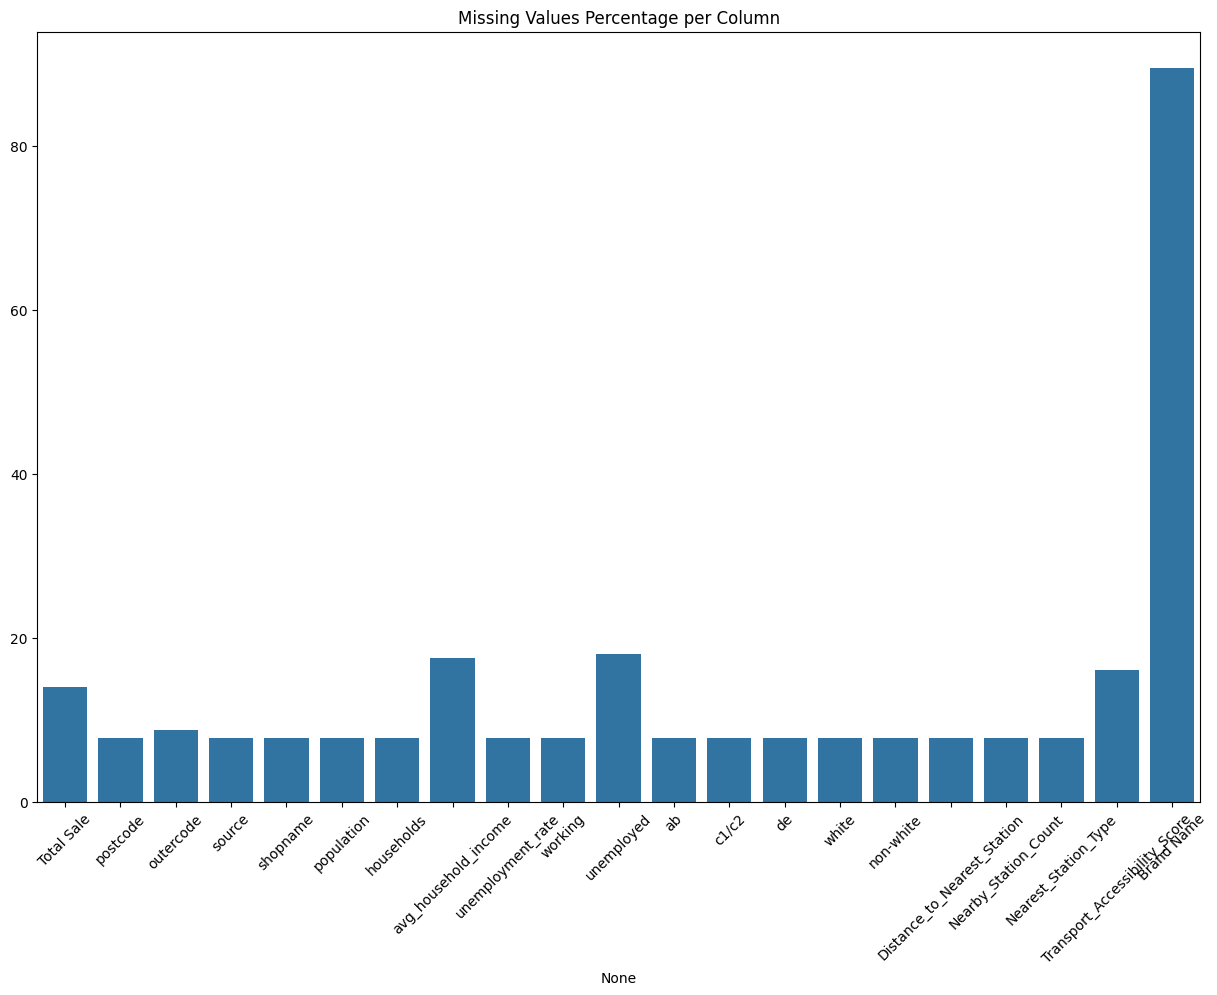

In [51]:
missing = df.isnull().sum()
missing = missing[missing > 0]
if not missing.empty:
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
    print(missing_df.sort_values(by='Percentage', ascending=False))
    
    plt.figure(figsize=(15, 10))
    sns.barplot(x=missing_pct.index, y=missing_pct.values)
    plt.xticks(rotation=45)
    plt.title("Missing Values Percentage per Column")
    plt.show()
else:
    print("No missing values found!")

### 2.3 Numerical Definitions & Distributions

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Total Sale,78838.0,771.138373,513.144901,0.000,383.5925,707.315,1055.9275,10465.1900
population,84557.0,67720.359343,41277.585510,0.000,33898.0000,53127.000,103380.0000,180271.0000
households,84557.0,26908.403479,17003.090190,0.000,14028.0000,19596.000,43104.0000,70953.0000
avg_household_income,75589.0,37892.671764,11244.342299,0.000,31980.0000,34710.000,45032.0000,62284.0000
unemployment_rate,84557.0,0.081613,0.047704,0.000,0.0500,0.080,0.0989,0.2366
working,84557.0,0.748163,0.143425,0.170,0.7300,0.770,0.8500,1.0000
unemployed,75161.0,0.215640,0.119539,0.000,0.1300,0.210,0.2400,0.8300
ab,84557.0,0.221821,0.090812,0.000,0.1600,0.210,0.2800,0.4700
c1/c2,84557.0,0.453146,0.105716,0.000,0.4300,0.490,0.5200,0.5600
de,84557.0,0.287898,0.112872,0.000,0.2300,0.260,0.3300,0.8270


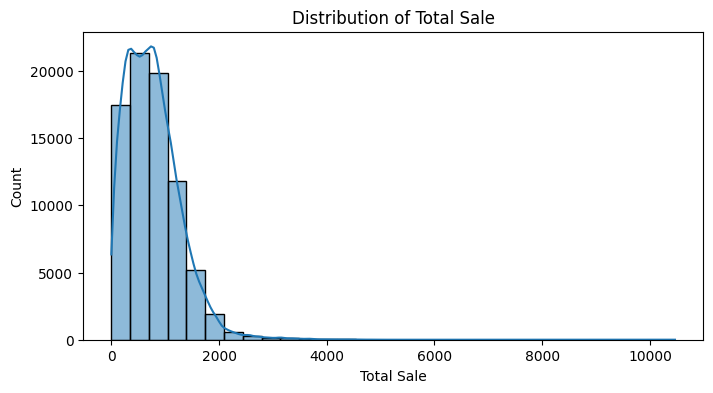

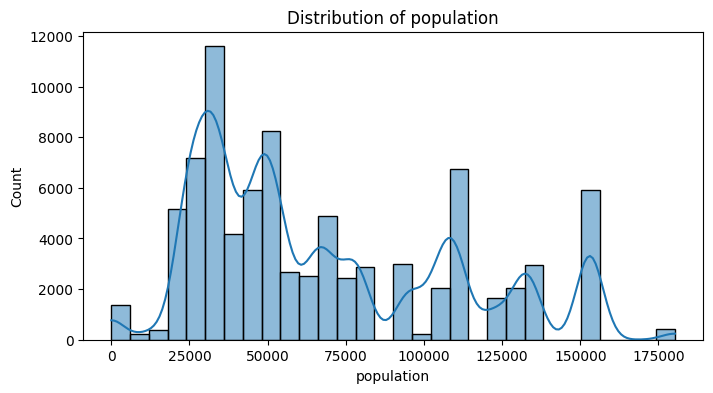

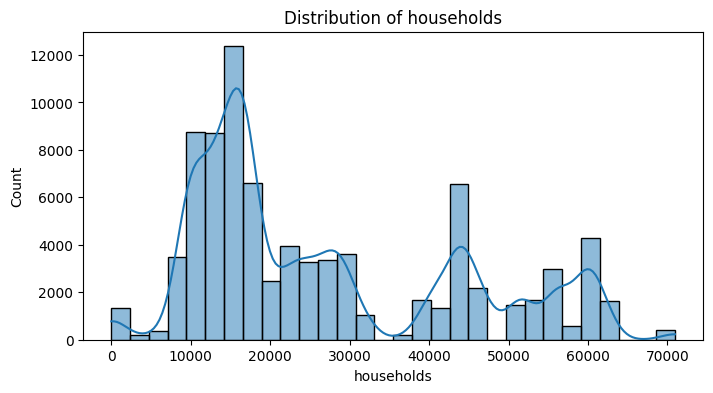

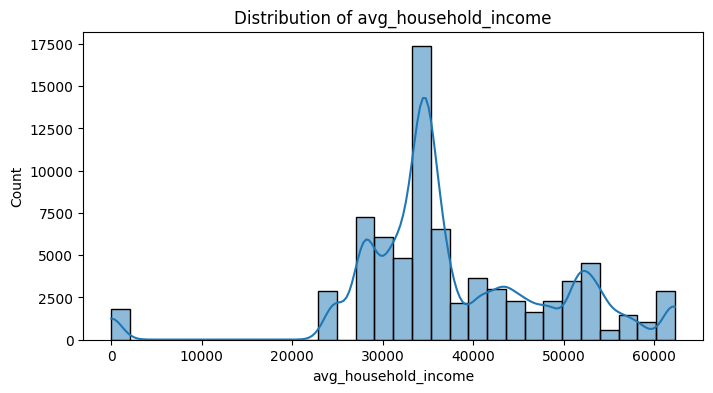

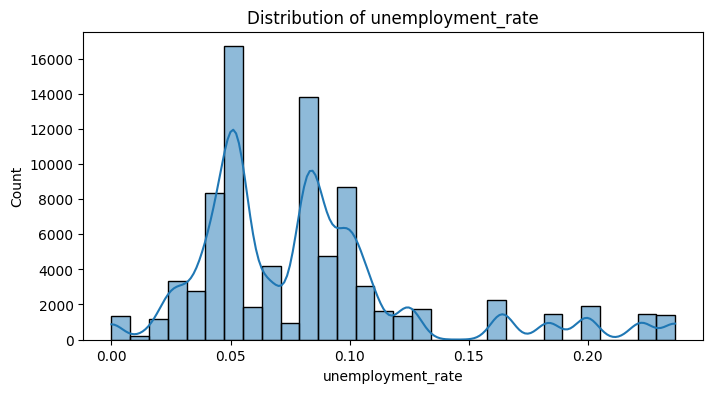

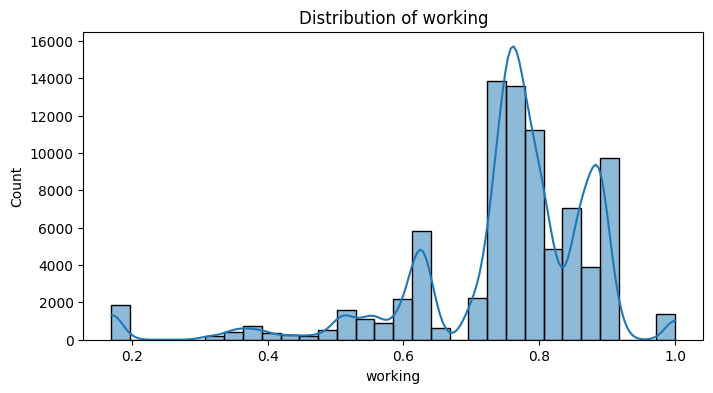

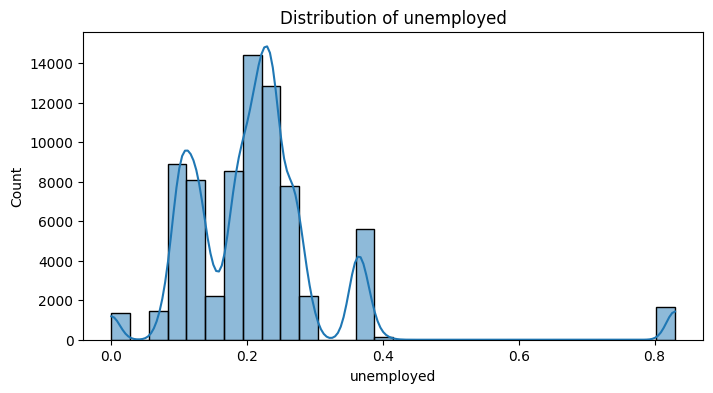

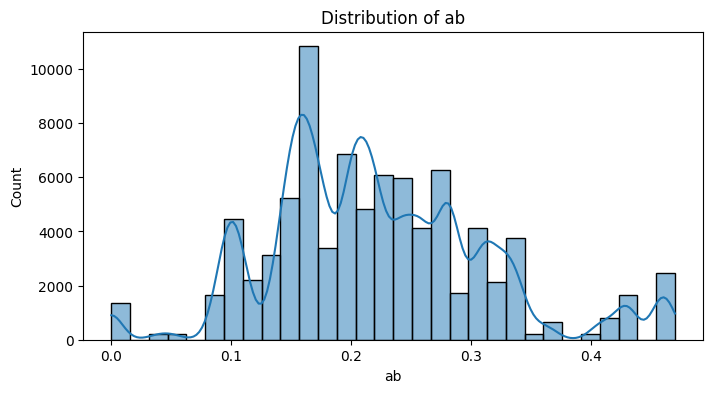

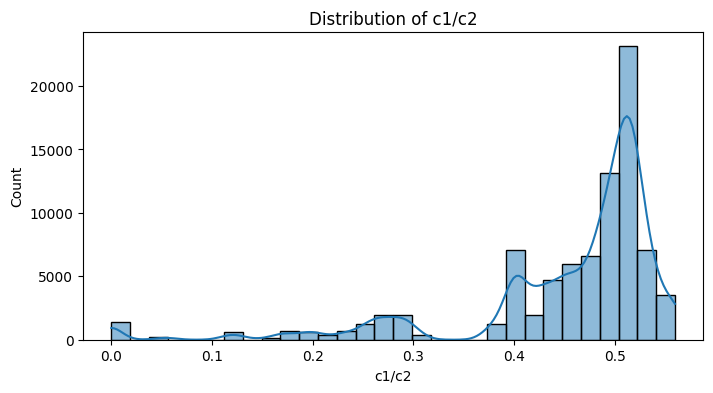

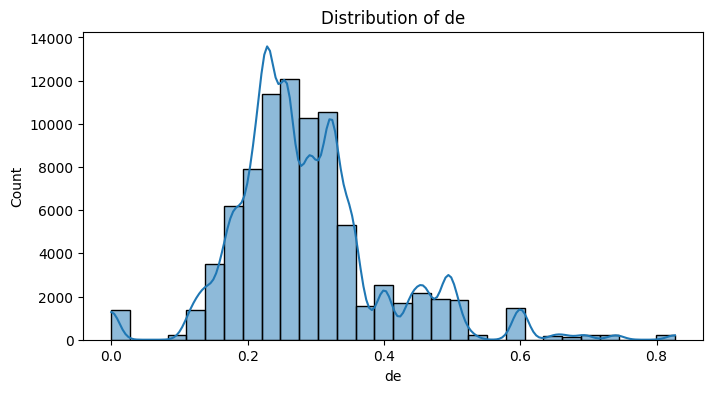

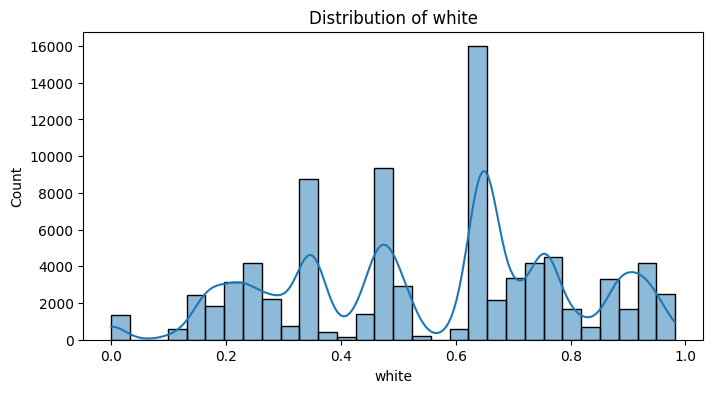

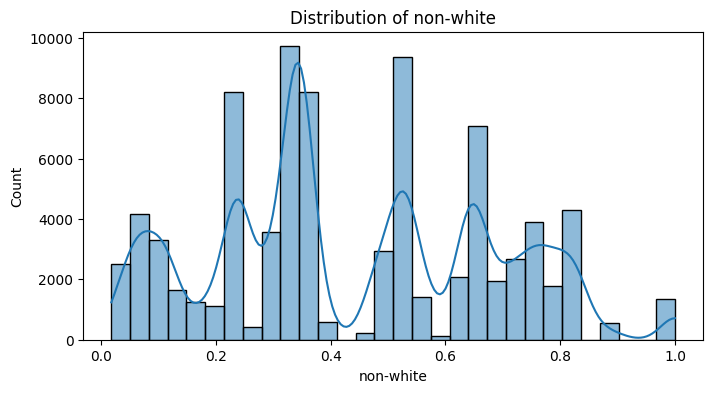

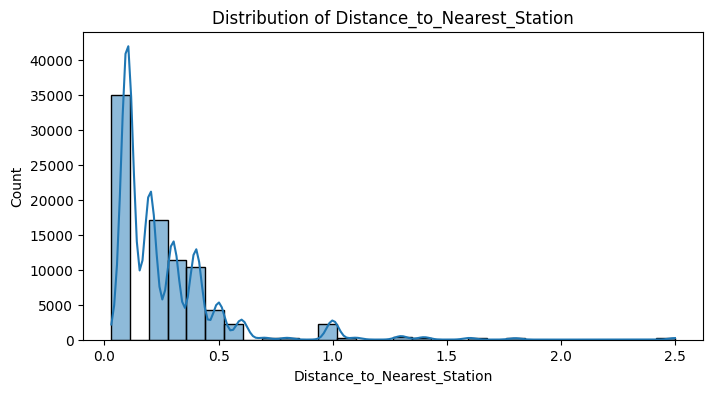

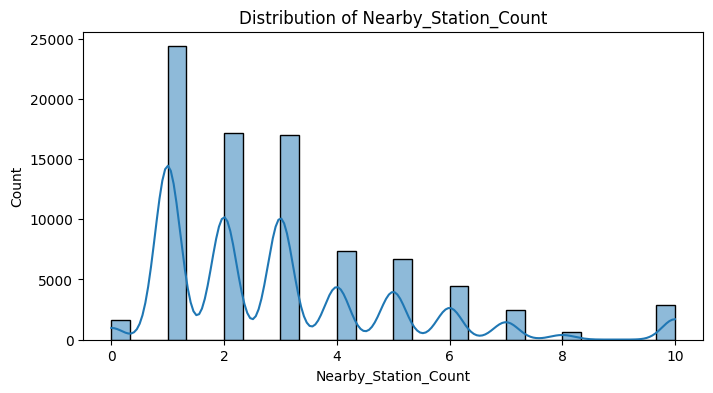

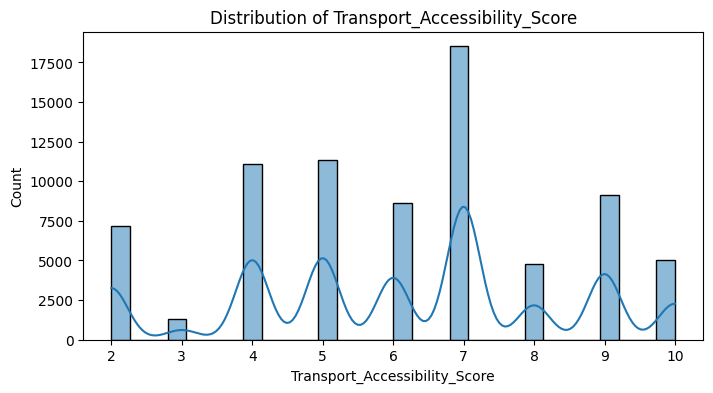

In [7]:
# Visualize distributions of key numerical features
num_cols = df.select_dtypes(include=[np.number]).columns
num_cols = [c for c in num_cols if 'Date' not in c] # Exclude date if mistakenly num

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.show()

### 2.4 Categorical Analysis

In [8]:
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    print(f"\nUnique values in {col}: {df[col].nunique()}")
    print(df[col].value_counts().head(10))


Unique values in Day_of_Week: 7
Day_of_Week
Mon    22881
Sat    11525
Fri    11494
Wed    11459
Tue    11457
Sun    11455
Thu    11430
Name: count, dtype: int64

Unique values in Date: 3349
Date
2024-10-04 00:00:00    76
2024-10-05 00:00:00    76
2024-10-07 00:00:00    76
2024-10-08 00:00:00    76
2024-10-09 00:00:00    76
2024-10-10 00:00:00    76
2024-10-11 00:00:00    76
2024-10-12 00:00:00    76
2024-10-15 00:00:00    76
2024-10-17 00:00:00    76
Name: count, dtype: int64

Unique values in Branch Name: 130
Branch Name
rio's piri piri coventry        5924
rio's piri piri northampton     2029
rio's piri piri lozells         1785
rio's piri piri forge           1764
maeme's bristol                 1663
rio's piri piri warrington      1663
rio's piri piri watford         1663
rio's piri piri leicester       1663
rio's piri piri lisson grove    1663
rio's piri piri redditch        1663
Name: count, dtype: int64

Unique values in postcode: 75
postcode
CV1 3GJ     3177
CV6 5AU     3176
N

C:\Users\USER\AppData\Local\Temp\ipykernel_9444\650040304.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


### 2.5 Target Variable Analysis (Total Sale)

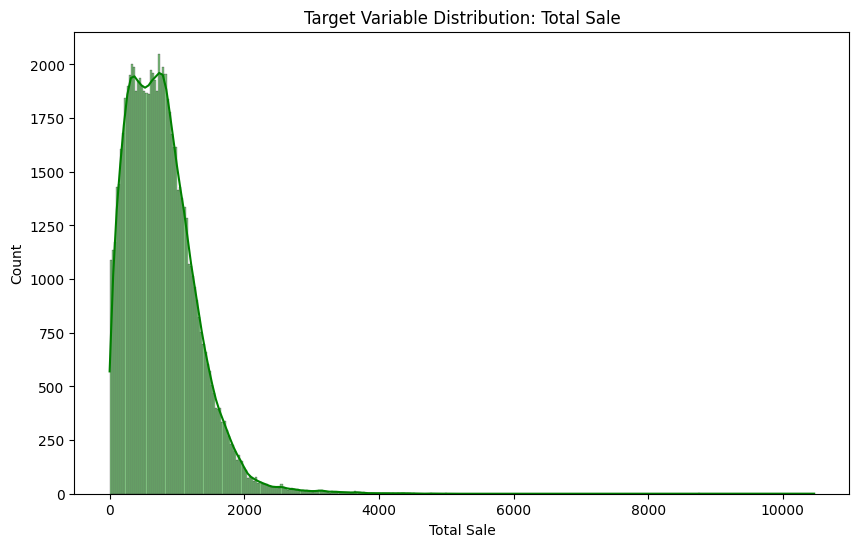

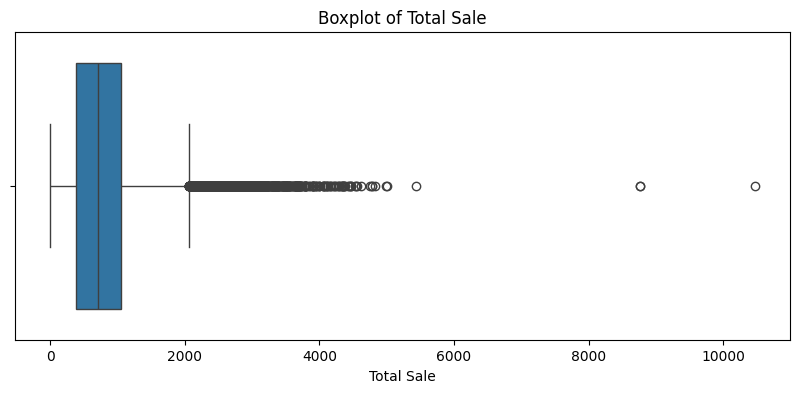

In [9]:
target = 'Total Sale'
if target in df.columns:
    plt.figure(figsize=(10, 6))
    sns.histplot(df[target], kde=True, color='green')
    plt.title("Target Variable Distribution: Total Sale")
    plt.show()
    
    # Boxplot to check for outliers
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[target])
    plt.title("Boxplot of Total Sale")
    plt.show()

### 2.6 Correlations

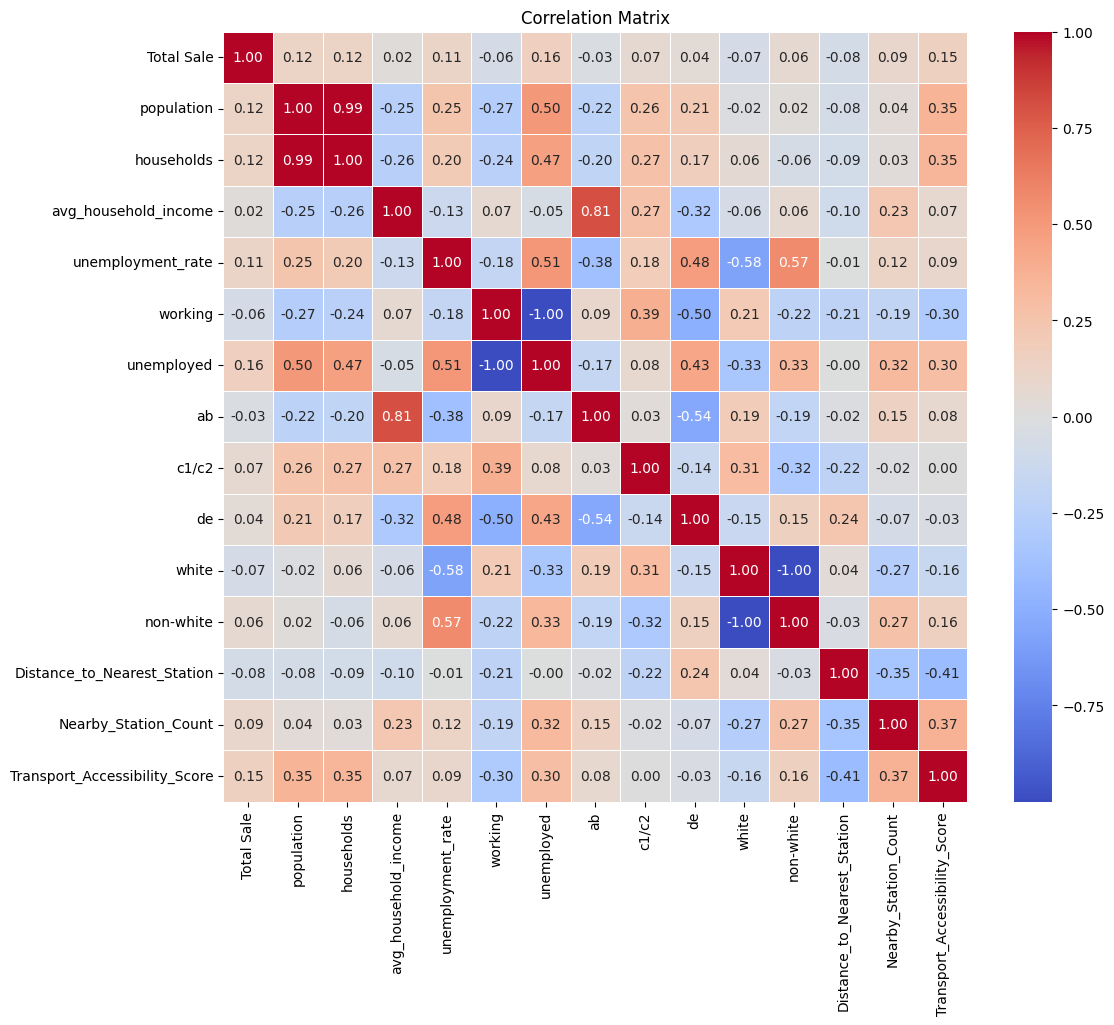

In [10]:
if len(num_cols) > 1:
    plt.figure(figsize=(12, 10))
    corr = df[num_cols].corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title("Correlation Matrix")
    plt.show()

## 3. Advanced Analysis & Problem Detection


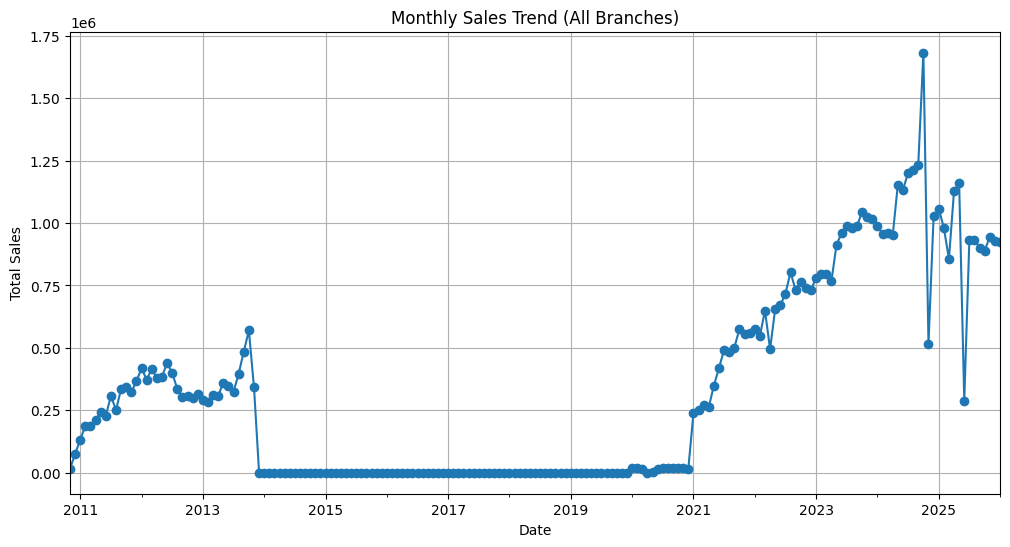

In [11]:
# 3.1 Time Series Trend (Monthly Sales)
try:
    if not pd.api.types.is_datetime64_any_dtype(df['Date']):
        # Use format='mixed' to handle the different date string formats gracefully
        df['Date'] = pd.to_datetime(df['Date'], format='mixed', errors='coerce')
        
    monthly_sales = df.set_index('Date').resample('ME')['Total Sale'].sum()
    plt.figure(figsize=(12, 6))
    monthly_sales.plot(marker='o', linestyle='-')
    plt.title('Monthly Sales Trend (All Branches)')
    plt.ylabel('Total Sales')
    plt.grid(True)
    plt.show()
except Exception as e:
    print(f"Could not plot time series: {e}")


C:\Users\USER\AppData\Local\Temp\ipykernel_9444\1810087956.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=branch_sales.head(10).values, y=branch_sales.head(10).index, palette='viridis')


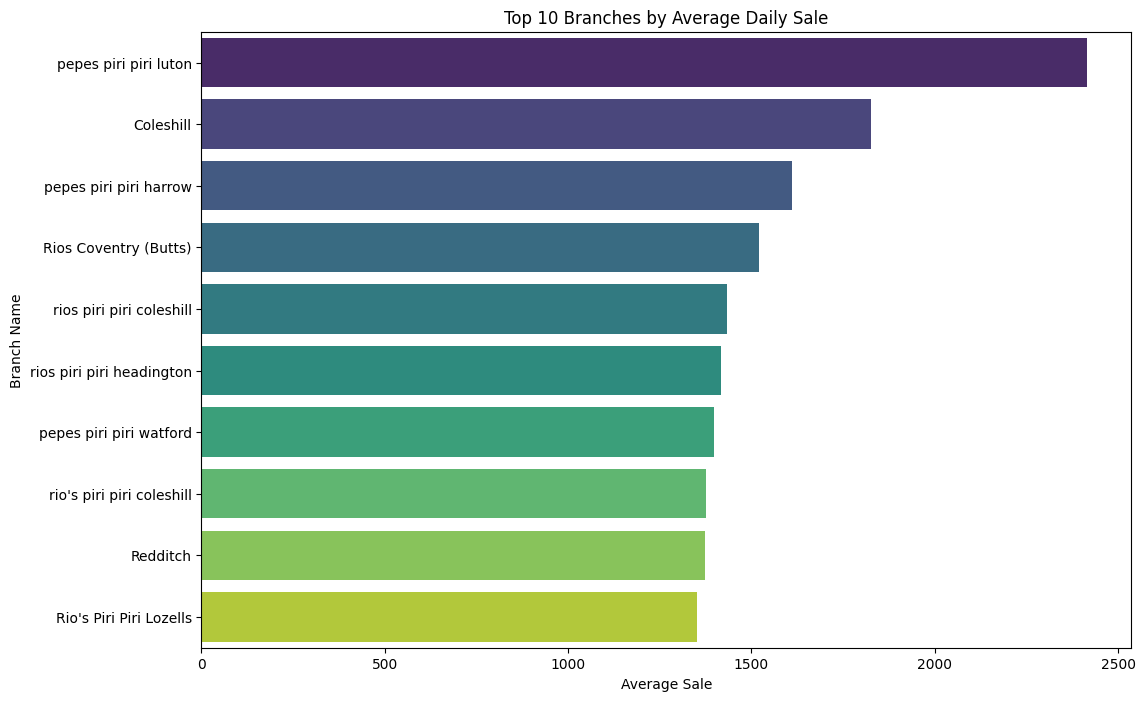

Top 5 Branches:
Branch Name
pepes piri piri luton       2415.306907
Coleshill                   1824.922710
pepes piri piri harrow      1611.590581
Rios Coventry (Butts)       1519.932140
rios piri piri coleshill    1434.378508
Name: Total Sale, dtype: float64

Bottom 5 Branches:
Branch Name
Aston Street        121.830000
maeme's watford     112.723397
Derby                82.698607
maeme's aberdeen     47.048368
Aberdeen             32.557667
Name: Total Sale, dtype: float64


In [12]:
# 3.2 Top & Bottom Performing Branches
branch_sales = df.groupby('Branch Name')['Total Sale'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 8))
sns.barplot(x=branch_sales.head(10).values, y=branch_sales.head(10).index, palette='viridis')
plt.title('Top 10 Branches by Average Daily Sale')
plt.xlabel('Average Sale')
plt.show()
print('Top 5 Branches:')
print(branch_sales.head(5))
print('\nBottom 5 Branches:')
print(branch_sales.tail(5))


In [13]:
# 3.3 Zero Value Quality Check
cols = ['population', 'households', 'avg_household_income']
for col in cols:
    zeros = (df[col] == 0).sum()
    if zeros > 0:
        print(f"\nColumn '{col}' has {zeros} zeros.")
        print(f"Affected: {df[df[col] == 0]['Branch Name'].unique()[:5]}...")



Column 'population' has 1358 zeros.
Affected: <StringArray>
['rio's piri piri linwood', 'rio's piri piri hamilton']
Length: 2, dtype: str...

Column 'households' has 1358 zeros.
Affected: <StringArray>
['rio's piri piri linwood', 'rio's piri piri hamilton']
Length: 2, dtype: str...

Column 'avg_household_income' has 1786 zeros.
Affected: <StringArray>
['rio's piri piri linwood', 'rio's piri piri hamilton', 'Main']
Length: 3, dtype: str...


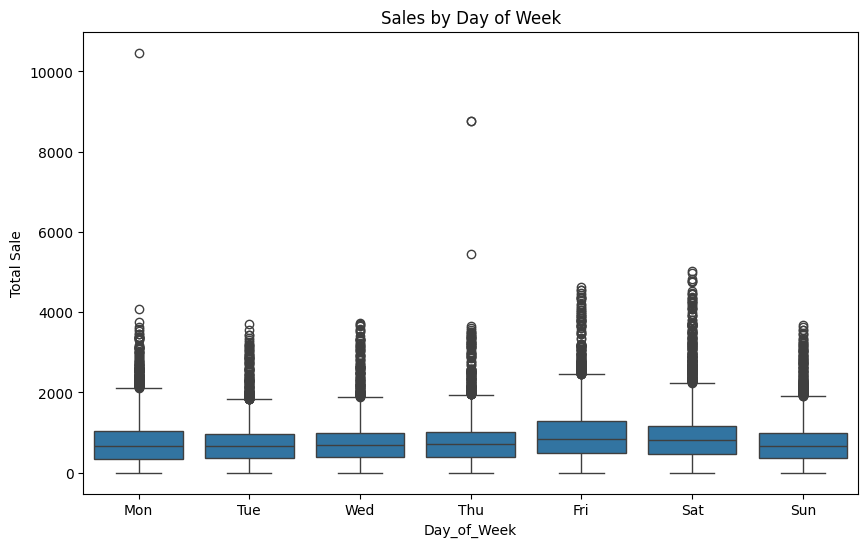

In [14]:
# 3.4 Day of Week Analysis
order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
plt.figure(figsize=(10, 6))
sns.boxplot(x='Day_of_Week', y='Total Sale', data=df, order=order)
plt.title('Sales by Day of Week')
plt.show()


## 4. Data Cleaning


In [15]:
# 4.1 Separate Historical vs Prediction Data
# We only want to evaluate and drop targets on Historical Data.
df_hist = df[df['Dataset'] == 'Historical'].copy()
df_pred = df[df['Dataset'] == 'Prediction'].copy()
print(f"Historical shape: {df_hist.shape}")
print(f"Prediction shape: {df_pred.shape}")


Historical shape: (82091, 25)
Prediction shape: (9610, 25)


In [16]:
# 4.2 Drop Missing Targets (Total Sale) from Historical
initial_len = len(df_hist)
df_hist = df_hist.dropna(subset=['Total Sale'])
dropped = initial_len - len(df_hist)
print(f"Dropped {dropped} rows with missing Total Sale in Historical data.")
print(f"New Historical shape: {df_hist.shape}")


Dropped 12863 rows with missing Total Sale in Historical data.
New Historical shape: (69228, 25)


In [17]:
# 4.3 Recombine for Joint Feature Engineering/Imputation
df_clean = pd.concat([df_hist, df_pred], ignore_index=True)
print(f"Cleaned Combined shape: {df_clean.shape}")


Cleaned Combined shape: (78838, 25)


In [18]:
# 4.4 Fix Invalid Zeros
cols_to_check = ['population', 'households', 'avg_household_income', 'unemployment_rate', 
                 'working', 'unemployed', 'ab', 'c1/c2', 'de', 'white', 'non-white']
for col in cols_to_check:
    # Replace 0s with NaN so the imputer can handle them
    zero_count = (df_clean[col] == 0).sum()
    if zero_count > 0:
        df_clean.loc[df_clean[col] == 0, col] = np.nan
        print(f"Replaced {zero_count} zeros with NaN in {col}")


Replaced 758 zeros with NaN in population
Replaced 758 zeros with NaN in households
Replaced 1186 zeros with NaN in avg_household_income
Replaced 758 zeros with NaN in unemployment_rate
Replaced 758 zeros with NaN in unemployed
Replaced 758 zeros with NaN in ab
Replaced 758 zeros with NaN in c1/c2
Replaced 758 zeros with NaN in de
Replaced 758 zeros with NaN in white


In [19]:
# 4.5 Clean missing transport data
transport_cols = ['Distance_to_Nearest_Station', 'Nearby_Station_Count', 'Nearest_Station_Type', 'Transport_Accessibility_Score']
print("Missing Transport data before:", df_clean[transport_cols].isna().sum().sum())
for col in transport_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median() if df_clean[col].dtype in ['float64', 'int64'] else 'Unknown')


Missing Transport data before: 30310


## 5. Feature Engineering
Here we apply the specific strategies defined in our `column_strategy_table.md` to fix distribution skews, handle multimodal data, and scale features robustly.


In [20]:
# 5.1 Continuous Log-Normal Features (Log1p & Sqrt)
import numpy as np

# Log1p Transformation to fix severe right skew / extreme ranges
# --- OOD FIX FOR SMALL BRANCHES (e.g., 'Main') ---
# We cap population to a minimum of 30,000 so the model doesn't assume a town of 12k will automatically fail.
if 'population' in df_clean.columns:
    df_clean['population'] = df_clean['population'].clip(lower=30000)
    print('Capped population minimum to 30,000 to prevent XGBoost ghost-town penalty.')

log_cols = ['population', 'households', 'Distance_to_Nearest_Station']
for col in log_cols:
    if col in df_clean.columns:
        df_clean[col] = np.log1p(df_clean[col])
        print(f"Applied log1p to {col}")

# Square Root Transformation for zero-inflated count data
if 'Nearby_Station_Count' in df_clean.columns:
    df_clean['Nearby_Station_Count'] = np.sqrt(df_clean['Nearby_Station_Count'])
    print("Applied sqrt to Nearby_Station_Count")


Capped population minimum to 30,000 to prevent XGBoost ghost-town penalty.
Applied log1p to population
Applied log1p to households
Applied log1p to Distance_to_Nearest_Station
Applied sqrt to Nearby_Station_Count


In [21]:
# 5.2 Multimodal / Spiky Data Discretization
from sklearn.preprocessing import KBinsDiscretizer, QuantileTransformer

# Quantile Binning for 'non-white' (due to distinct regional peaks)
if 'non-white' in df_clean.columns:
    qt = QuantileTransformer(n_quantiles=10, output_distribution='uniform', random_state=42)
    # Fill NaNs temporarily for fit_transform, or we can transform directly if we mask NaNs.
    mask = df_clean['non-white'].notna()
    df_clean.loc[mask, 'non-white_quantile'] = qt.fit_transform(df_clean.loc[mask, ['non-white']])
    print("Applied QuantileTransformer to non-white")

# KMeans Discretizer for 'unemployed', 'ab', 'de' (these exist in natural brackets)
kmeans_cols = ['unemployed', 'ab', 'de']
kbd = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='kmeans')
available_cols = [c for c in kmeans_cols if c in df_clean.columns]
if len(available_cols) > 0:
    mask = df_clean[available_cols].notna().all(axis=1)
    if mask.sum() > 0:
        transformed = kbd.fit_transform(df_clean.loc[mask, available_cols])
        for idx, col in enumerate(available_cols):
            df_clean.loc[mask, f'{col}_kmeans_bin'] = transformed[:, idx]
        print(f"Applied KMeans KBinsDiscretizer to {available_cols} simultaneously")



Applied QuantileTransformer to non-white
Applied KMeans KBinsDiscretizer to ['unemployed', 'ab', 'de'] simultaneously


In [22]:
# 5.3 Left Skewed Data (Yeo-Johnson Transformation)
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method='yeo-johnson')

yeo_cols = ['working', 'c1/c2']
available_yeo = [c for c in yeo_cols if c in df_clean.columns]
if len(available_yeo) > 0:
    mask = df_clean[available_yeo].notna().all(axis=1)
    if mask.sum() > 0:
        transformed = pt.fit_transform(df_clean.loc[mask, available_yeo])
        for idx, col in enumerate(available_yeo):
            df_clean.loc[mask, col] = transformed[:, idx]
        print(f"Applied Yeo-Johnson transform to {available_yeo} simultaneously")


Applied Yeo-Johnson transform to ['working', 'c1/c2'] simultaneously


In [23]:
# 5.4 Outlier-Heavy Data (Robust Scaler)
from sklearn.preprocessing import RobustScaler
rs = RobustScaler()

if 'avg_household_income' in df_clean.columns:
    mask = df_clean['avg_household_income'].notna()
    if mask.sum() > 0:
        df_clean.loc[mask, 'avg_household_income'] = rs.fit_transform(df_clean.loc[mask, ['avg_household_income']])
        print("Applied RobustScaler to avg_household_income")


Applied RobustScaler to avg_household_income


In [24]:
# 5.5 Handling Suspicious Zeros (unemployment_rate)
if 'unemployment_rate' in df_clean.columns:
    # Add a flag for where it was originally missing/zero (we set zeros to NaN in cleaning phase)
    df_clean['unemployment_rate_is_missing'] = df_clean['unemployment_rate'].isna().astype(int)
    # Let the ML Imputer (next step/pipeline) handle the actual mean imputation, just created the flag for now.
    print("Created missing flag for unemployment_rate")


Created missing flag for unemployment_rate


In [25]:
# 5.6 Transport Accessibility Score & Date Features
from sklearn.preprocessing import OrdinalEncoder
# Ordinal Integer Encoding for Transport_Accessibility_Score
if 'Transport_Accessibility_Score' in df_clean.columns:
    mask = df_clean['Transport_Accessibility_Score'].notna()
    oe = OrdinalEncoder()
    df_clean.loc[mask, 'Transport_Accessibility_Score'] = oe.fit_transform(df_clean.loc[mask, ['Transport_Accessibility_Score']])
    print("Applied Ordinal Encoding to Transport_Accessibility_Score")

# Extracting Dates
if not pd.api.types.is_datetime64_any_dtype(df_clean['Date']):
    df_clean['Date'] = pd.to_datetime(df_clean['Date'], errors='coerce', format='mixed')
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Dayofweek'] = df_clean['Date'].dt.dayofweek
df_clean['Is_Weekend'] = df_clean['Dayofweek'].apply(lambda x: 1 if x >= 5 else 0)
print("Extracted Date features")


Applied Ordinal Encoding to Transport_Accessibility_Score
Extracted Date features


In [26]:
df_clean.head()


,Day_of_Week,Date,Branch Name,Total Sale,postcode,outercode,source,shopname,population,households,avg_household_income,unemployment_rate,working,unemployed,ab,c1/c2,de,white,non-white,Distance_to_Nearest_Station,Nearby_Station_Count,Nearest_Station_Type,Transport_Accessibility_Score,Dataset,Brand Name,non-white_quantile,unemployed_kmeans_bin,ab_kmeans_bin,de_kmeans_bin,unemployment_rate_is_missing,Year,Month,Dayofweek,Is_Weekend
0,Fri,2010-11-12,pepes piri piri harrow,1150.37,HA1 2TB,HA1,Pepes,Harrow,10.880459,9.804882,1.190692,0.0953,0.192363,0.21,0.29,-0.213973,0.22,0.24,0.75,0.262364,2.0,Train Station,6.0,Historical,NaN,0.87037,1.0,2.0,1.0,0,2010,11,4,0
1,Sat,2010-11-13,pepes piri piri harrow,873.58,HA1 2TB,HA1,Pepes,Harrow,10.880459,9.804882,1.190692,0.0953,0.192363,0.21,0.29,-0.213973,0.22,0.24,0.75,0.262364,2.0,Train Station,6.0,Historical,NaN,0.87037,1.0,2.0,1.0,0,2010,11,5,1
2,Mon,2010-11-15,pepes piri piri harrow,769.22,HA1 2TB,HA1,Pepes,Harrow,10.880459,9.804882,1.190692,0.0953,0.192363,0.21,0.29,-0.213973,0.22,0.24,0.75,0.262364,2.0,Train Station,6.0,Historical,NaN,0.87037,1.0,2.0,1.0,0,2010,11,0,0
3,Tue,2010-11-16,pepes piri piri harrow,667.15,HA1 2TB,HA1,Pepes,Harrow,10.880459,9.804882,1.190692,0.0953,0.192363,0.21,0.29,-0.213973,0.22,0.24,0.75,0.262364,2.0,Train Station,6.0,Historical,NaN,0.87037,1.0,2.0,1.0,0,2010,11,1,0
4,Wed,2010-11-17,pepes piri piri harrow,492.51,HA1 2TB,HA1,Pepes,Harrow,10.880459,9.804882,1.190692,0.0953,0.192363,0.21,0.29,-0.213973,0.22,0.24,0.75,0.262364,2.0,Train Station,6.0,Historical,NaN,0.87037,1.0,2.0,1.0,0,2010,11,2,0


## 6. Verifying Transformed Distributions
Let's review the shape of the data after applying the Log1p, KMeans, and Yeo-Johnson transformations.


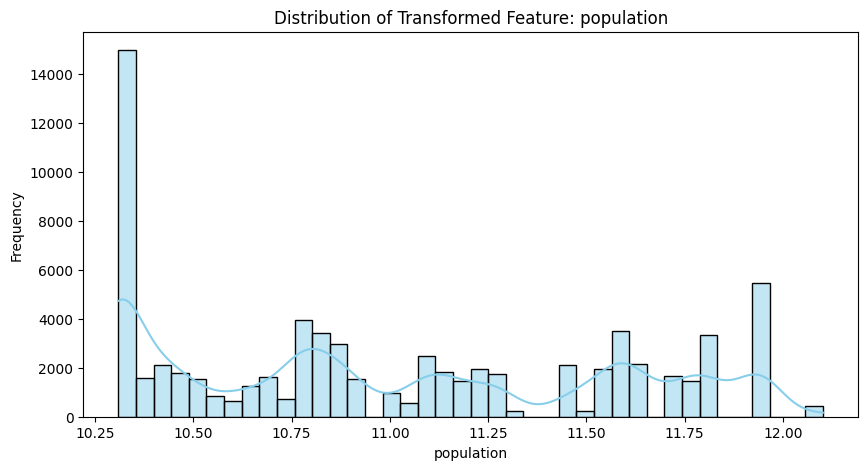

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'population'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


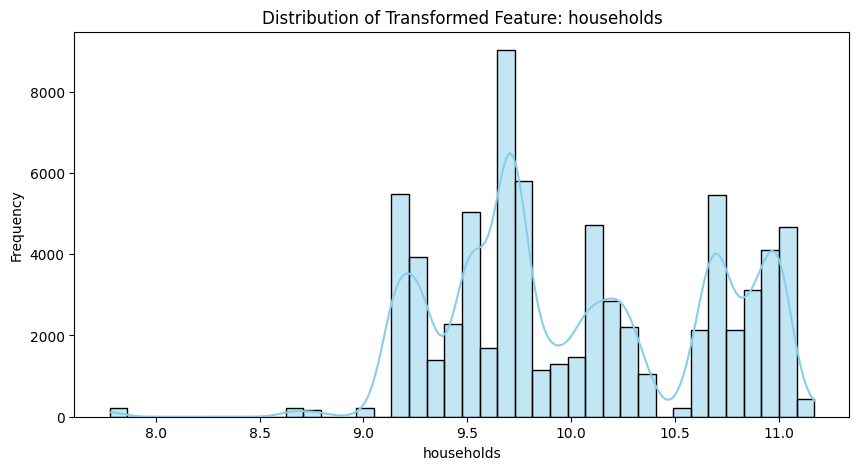

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'households'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


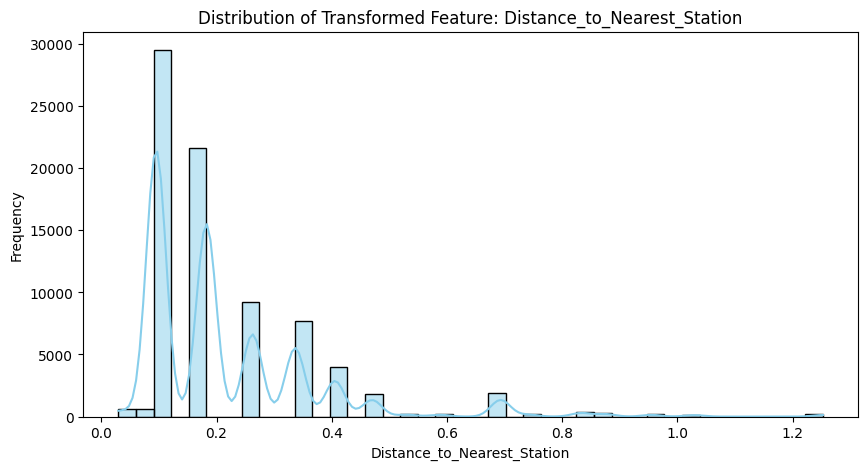

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'Distance_to_Nearest_Station'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


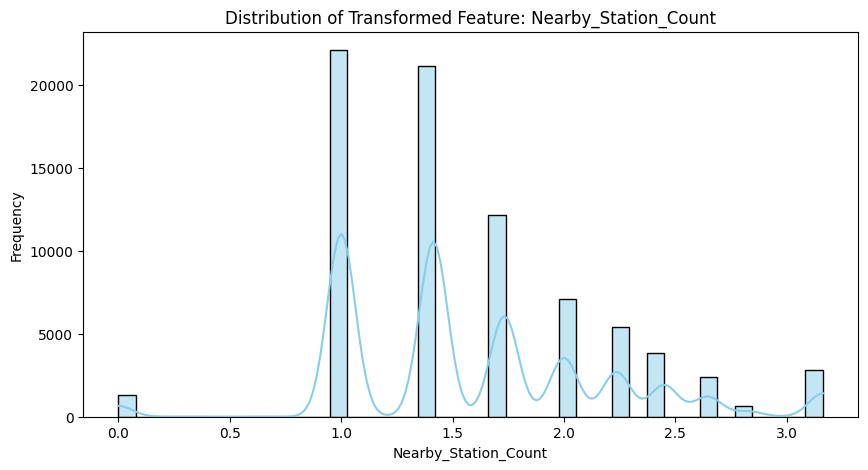

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'Nearby_Station_Count'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


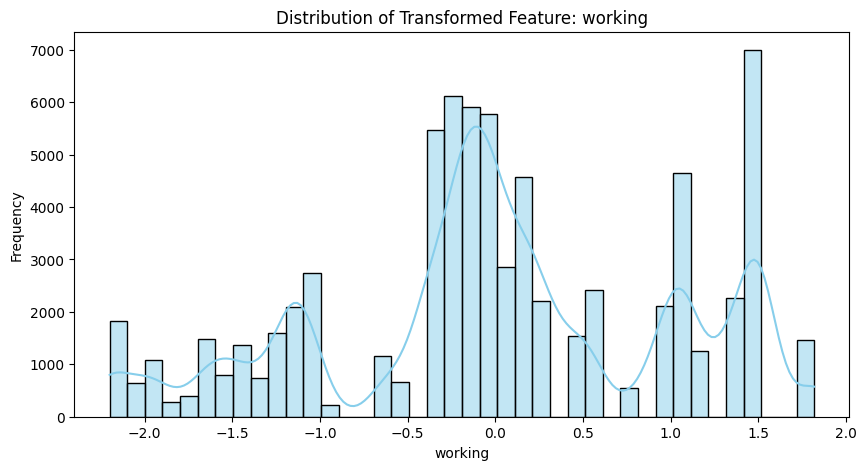

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'working'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


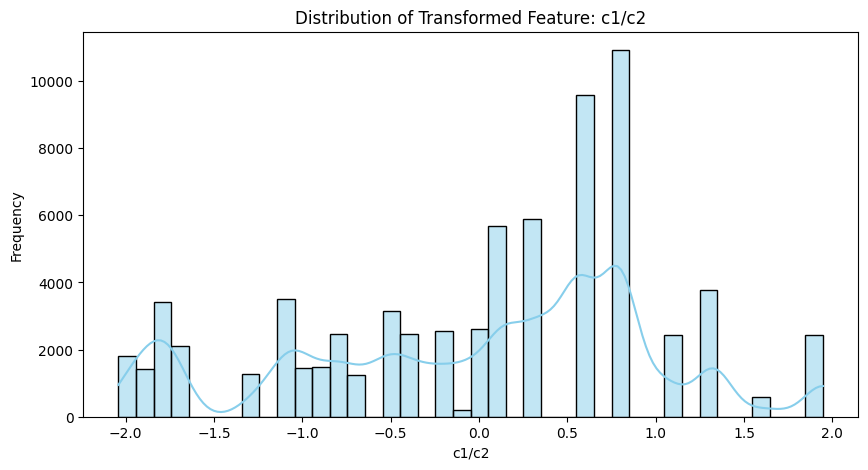

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'c1/c2'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


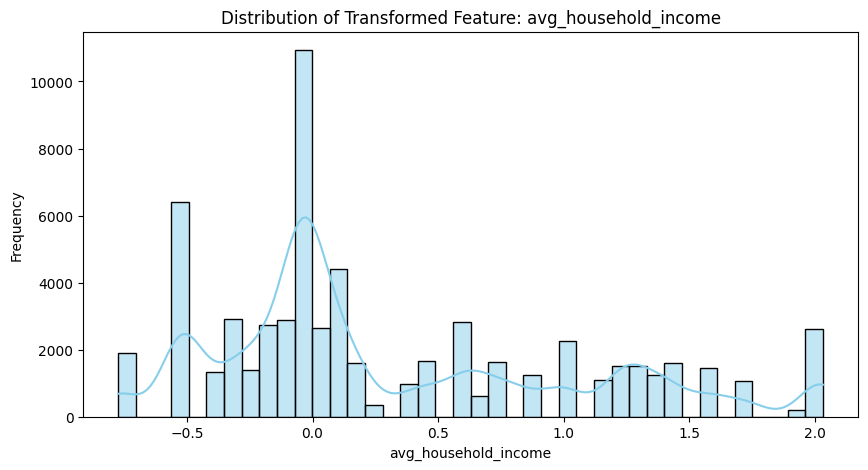

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'avg_household_income'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


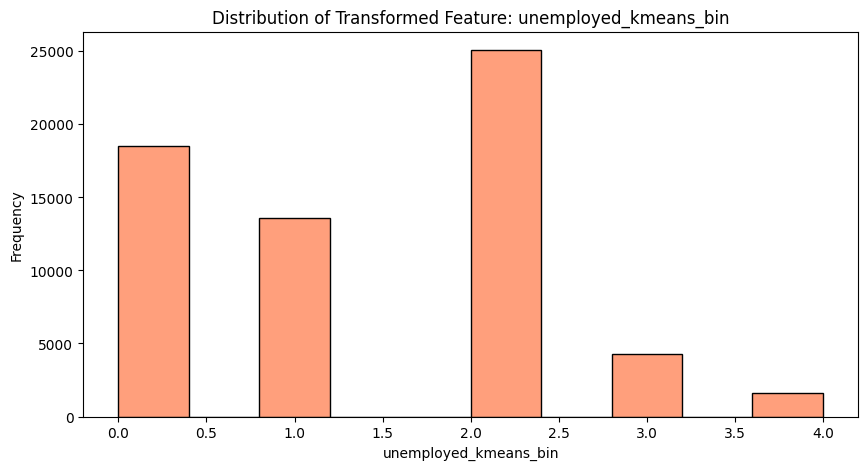

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'unemployed_kmeans_bin'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


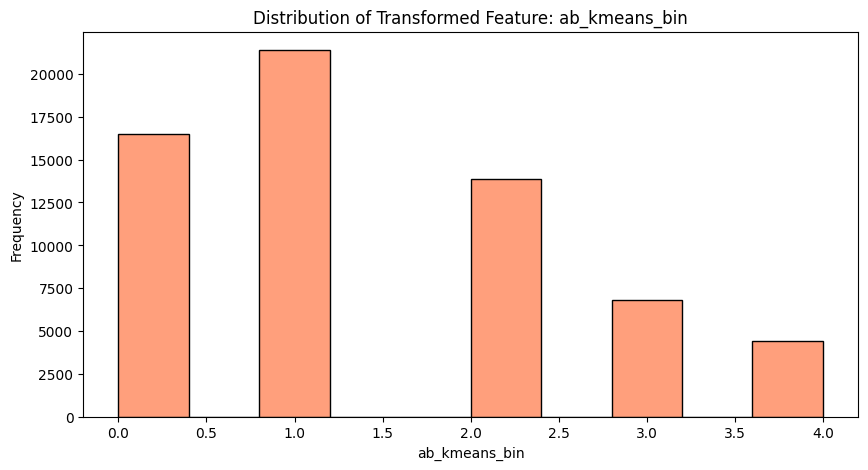

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'ab_kmeans_bin'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


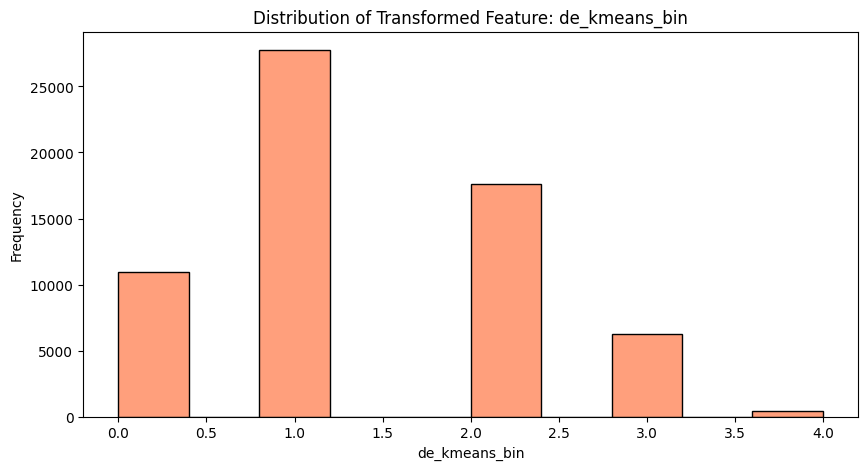

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'de_kmeans_bin'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


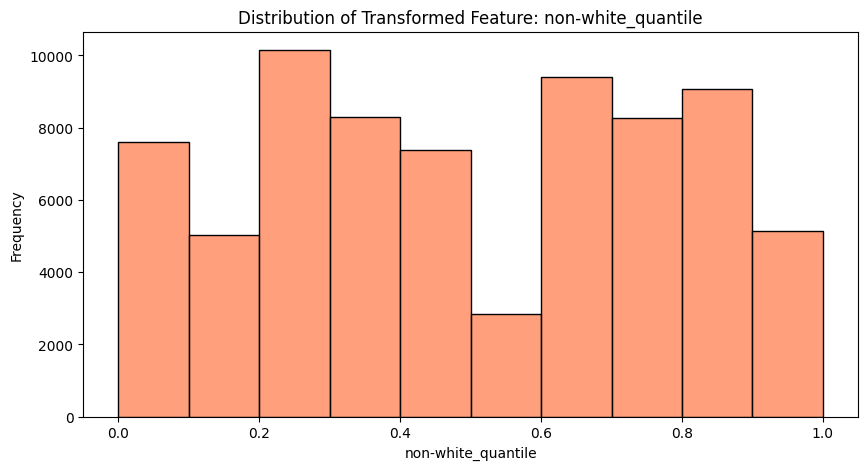

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

col = 'non-white_quantile'
if col in df_clean.columns:
    plt.figure(figsize=(10, 5))
    if 'bin' in col or 'quantile' in col:
        sns.histplot(df_clean[col].dropna(), bins=10, kde=False, color='coral')
    else:
        sns.histplot(df_clean[col].dropna(), bins=40, kde=True, color='skyblue')
    plt.title(f"Distribution of Transformed Feature: {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
else:
    print(f"Column {col} not found in dataframe.")


## 7. Comprehensive Baseline Evaluation
We will separate the model training into individual cells. Fast models (Linear, KNN) will execute instantly, while tree-based models will output live progress during training.


In [38]:
# 7.1 Prepare Final Features and Preprocessor Pipeline
import numpy as np
import pandas as pd
import time
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Global results list that we will append to in each cell
results = []

cols_to_drop = ['Date', 'Branch Name', 'postcode', 'outercode', 'source', 
                'shopname', 'Dataset', 'Brand Name', 'Total Sale']

df_hist = df_clean[df_clean['Dataset'] == 'Historical'].copy()
df_pred = df_clean[df_clean['Dataset'] == 'Prediction'].copy()

X = df_hist.drop(columns=[c for c in cols_to_drop if c in df_hist.columns])
y = np.log1p(df_hist['Total Sale'])
X_pred = df_pred.drop(columns=[c for c in cols_to_drop if c in df_pred.columns])

categorical_features = ['Day_of_Week', 'Nearest_Station_Type']
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Scikit-Learn Strict Preprocessor (for Linear, KNN, RF)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features)
    ], remainder='passthrough'
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Global Data Setup Complete!")


Global Data Setup Complete!


### 7.2 Linear Models (Ridge, Lasso, ElasticNet)


In [39]:
# Ridge Regression (Trains instantly)
from sklearn.linear_model import Ridge

start = time.time()
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_processed, y_train)
preds = ridge_model.predict(X_test_processed)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'Ridge Regression', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"Ridge Regression | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


Ridge Regression | RMSE: 0.7669 | R2: 0.2151 | Time: 0.03s


In [40]:
# Lasso Regression
from sklearn.linear_model import Lasso

start = time.time()
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train_processed, y_train)
preds = lasso_model.predict(X_test_processed)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'Lasso Regression', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"Lasso Regression | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


Lasso Regression | RMSE: 0.8424 | R2: 0.0529 | Time: 0.05s


In [41]:
# ElasticNet
from sklearn.linear_model import ElasticNet

start = time.time()
en_model = ElasticNet(alpha=0.1, l1_ratio=0.5)
en_model.fit(X_train_processed, y_train)
preds = en_model.predict(X_test_processed)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'ElasticNet', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"ElasticNet | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


ElasticNet | RMSE: 0.8347 | R2: 0.0703 | Time: 0.09s


### 7.3 Distance-Based Model (KNN)


In [42]:
# K-Nearest Neighbors
from sklearn.neighbors import KNeighborsRegressor

start = time.time()
knn_model = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train_processed, y_train)
preds = knn_model.predict(X_test_processed)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'K-Nearest Neighbors', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"K-Nearest Neighbors | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


K-Nearest Neighbors | RMSE: 0.4553 | R2: 0.7233 | Time: 0.31s


### 7.4 Tree-Based Models (with Live Progress Tracking)


In [43]:
# Random Forest (Using verbose=2 for tree-building progress text logs)
from sklearn.ensemble import RandomForestRegressor

start = time.time()
print("Starting Random Forest Training (100 Trees)...")
rf_model = RandomForestRegressor(n_estimators=100, max_depth=100, n_jobs=-1, random_state=42, verbose=2)
rf_model.fit(X_train_processed, y_train)
preds = rf_model.predict(X_test_processed)

rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'Random Forest', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"\nRandom Forest | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


Starting Random Forest Training (100 Trees)...
building tree 1 of 100
building tree 2 of 100
building tree 3 of 100
building tree 4 of 100
building tree 5 of 100
building tree 6 of 100
building tree 7 of 100
building tree 8 of 100
building tree 9 of 100
building tree 10 of 100
building tree 11 of 100
building tree 12 of 100
building tree 13 of 100
building tree 14 of 100
building tree 15 of 100
building tree 16 of 100
building tree 17 of 100
building tree 18 of 100
building tree 19 of 100
building tree 20 of 100


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 20 concurrent workers.


building tree 21 of 100
building tree 22 of 100
building tree 23 of 100
building tree 24 of 100
building tree 25 of 100
building tree 26 of 100
building tree 27 of 100
building tree 28 of 100
building tree 29 of 100
building tree 30 of 100
building tree 31 of 100
building tree 32 of 100
building tree 33 of 100
building tree 34 of 100
building tree 35 of 100
building tree 36 of 100
building tree 37 of 100
building tree 38 of 100
building tree 39 of 100
building tree 40 of 100
building tree 41 of 100


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    0.1s


building tree 42 of 100building tree 43 of 100

building tree 44 of 100
building tree 45 of 100
building tree 46 of 100
building tree 47 of 100
building tree 48 of 100
building tree 49 of 100
building tree 50 of 100
building tree 51 of 100
building tree 52 of 100
building tree 53 of 100
building tree 54 of 100
building tree 55 of 100
building tree 56 of 100
building tree 57 of 100
building tree 58 of 100
building tree 59 of 100
building tree 60 of 100
building tree 61 of 100
building tree 62 of 100
building tree 63 of 100
building tree 64 of 100
building tree 65 of 100
building tree 66 of 100
building tree 67 of 100
building tree 68 of 100
building tree 69 of 100
building tree 70 of 100
building tree 71 of 100
building tree 72 of 100
building tree 73 of 100
building tree 74 of 100
building tree 75 of 100
building tree 76 of 100
building tree 77 of 100
building tree 78 of 100
building tree 79 of 100
building tree 80 of 100
building tree 81 of 100
building tree 82 of 100
building tree 83

[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    1.0s finished
[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished


In [44]:
# XGBoost (Using verbose=50 to print loss metrics every 50 epochs)
import xgboost as xgb

# XGBoost setup (Needs 'category' dtypes for native cat feature handling)
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()
for col in categorical_features:
    X_train_xgb[col] = X_train_xgb[col].astype('category')
    X_test_xgb[col] = X_test_xgb[col].astype('category')

start = time.time()
print("Starting XGBoost Training (300 Trees)...")
xgb_model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, enable_categorical=True, random_state=42, n_jobs=-1)

xgb_model.fit(
    X_train_xgb, y_train, 
    eval_set=[(X_test_xgb, y_test)], 
    verbose=50  # Prints out training progress and validation scores every 50 runs
)

preds = xgb_model.predict(X_test_xgb)
rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'XGBoost', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"\nXGBoost | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


Starting XGBoost Training (300 Trees)...
[0]	validation_0-rmse:0.82299
[50]	validation_0-rmse:0.45655
[100]	validation_0-rmse:0.43240
[150]	validation_0-rmse:0.41935
[200]	validation_0-rmse:0.41253
[250]	validation_0-rmse:0.40953
[299]	validation_0-rmse:0.40869

XGBoost | RMSE: 0.4087 | R2: 0.7771 | Time: 0.75s


In [45]:
# CatBoost (Using verbose=50 to print live evaluation metrics)
from catboost import CatBoostRegressor

# Fill NaNs with string 'Unknown' just in case for catboost string columns
X_train_cb = X_train.copy()
X_test_cb = X_test.copy()
for col in categorical_features:
    X_train_cb[col] = X_train_cb[col].fillna('Unknown').astype(str)
    X_test_cb[col] = X_test_cb[col].fillna('Unknown').astype(str)

start = time.time()
print("Starting CatBoost Training (300 Trees)...")
cb_model = CatBoostRegressor(iterations=300, learning_rate=0.1, depth=6, cat_features=categorical_features, random_seed=42, thread_count=-1)

cb_model.fit(
    X_train_cb, y_train, 
    eval_set=(X_test_cb, y_test),
    verbose=50 # Prints training/validation metric every 50 epochs
)

preds = cb_model.predict(X_test_cb)
rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'CatBoost', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"\nCatBoost | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")


Starting CatBoost Training (300 Trees)...
0:	learn: 0.8353418	test: 0.8246890	best: 0.8246890 (0)	total: 172ms	remaining: 51.4s
50:	learn: 0.5211591	test: 0.5040421	best: 0.5040421 (50)	total: 1.65s	remaining: 8.05s
100:	learn: 0.4789023	test: 0.4622244	best: 0.4622244 (100)	total: 3.13s	remaining: 6.17s
150:	learn: 0.4603332	test: 0.4448785	best: 0.4448785 (150)	total: 4.72s	remaining: 4.65s
200:	learn: 0.4493359	test: 0.4344727	best: 0.4344727 (200)	total: 6.19s	remaining: 3.05s


KeyboardInterrupt: 

In [ ]:
# LightGBM (Using Pandas Categorical for native cat feature handling)
import lightgbm as lgb
import time
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train_lgb = X_train.copy()
X_test_lgb = X_test.copy()

for col in categorical_features:
    X_train_lgb[col] = X_train_lgb[col].astype('category')
    X_test_lgb[col] = X_test_lgb[col].astype('category')

start = time.time()
print("Starting LightGBM Training (300 Trees)...")
lgb_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1)

# Fit model with evaluation
lgb_model.fit(
    X_train_lgb, y_train, 
    eval_set=[(X_test_lgb, y_test)]
)

preds = lgb_model.predict(X_test_lgb)
rmse = np.sqrt(mean_squared_error(y_test, preds))
mae = mean_absolute_error(y_test, preds)
r2 = r2_score(y_test, preds)
calc_time = time.time() - start

results.append({'Model': 'LightGBM', 'RMSE (Log)': rmse, 'MAE (Log)': mae, 'R2 Score': r2, 'Time (s)': calc_time})
print(f"\nLightGBM | RMSE: {rmse:.4f} | R2: {r2:.4f} | Time: {calc_time:.2f}s")

Starting LightGBM Training (300 Trees)...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001310 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 561
[LightGBM] [Info] Number of data points in the train set: 55382, number of used features: 25
[LightGBM] [Info] Start training from score 6.394668

LightGBM | RMSE: 0.4097 | R2: 0.7760 | Time: 0.40s


### 7.5 Baseline Leaderboard & Comparison



🏆 Baseline Leaderboard (Sorted by RMSE) 🏆


,Model,RMSE (Log),MAE (Log),R2 Score,Time (s)
0,XGBoost,0.408693,0.238967,0.777084,0.724041
1,LightGBM,0.409715,0.244746,0.775967,0.403661
2,CatBoost,0.425612,0.259658,0.758246,8.518987
3,Random Forest,0.435338,0.253080,0.747070,1.223550
4,K-Nearest Neighbors,0.455330,0.267346,0.723306,0.342228
5,Ridge Regression,0.766867,0.576222,0.215150,0.016026
6,ElasticNet,0.834651,0.616972,0.070271,0.068662
7,Lasso Regression,0.842392,0.624889,0.052945,0.035569


C:\Users\USER\AppData\Local\Temp\ipykernel_23352\2874160657.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='R2 Score', y='Model', data=results_df.sort_values(by='R2 Score', ascending=False), palette='viridis')


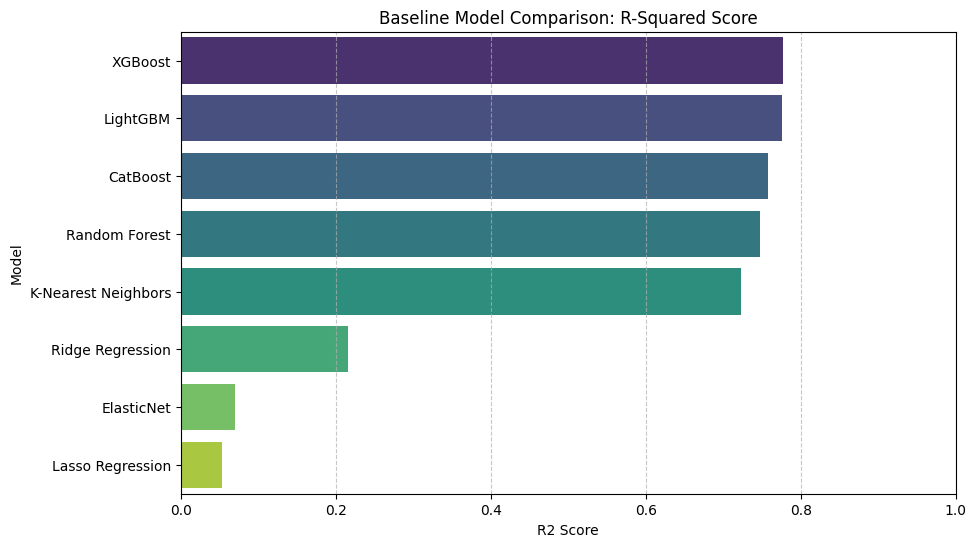

In [ ]:
# Visualize final metrics
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='RMSE (Log)', ascending=True).reset_index(drop=True)

print("\n🏆 Baseline Leaderboard (Sorted by RMSE) 🏆")
display(results_df)

plt.figure(figsize=(10, 6))
sns.barplot(x='R2 Score', y='Model', data=results_df.sort_values(by='R2 Score', ascending=False), palette='viridis')
plt.title('Baseline Model Comparison: R-Squared Score')
plt.xlim(0, 1.0)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


## 8. Hyperparameter Tuning (Multi-Model Optuna)\nWe will now use Bayesian Optimization to intelligently tune the hyperparameters for XGBoost, LightGBM, and CatBoost simultaneously so we can find the true champion model.

In [ ]:
# 8.1 Setup Optuna Objectives for All Models
import optuna
from catboost import CatBoostRegressor
import lightgbm as lgb
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import time

# 1. XGBoost Objective
def objective_xgb(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1000, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'gamma': trial.suggest_float('gamma', 0.0, 5.0),
        'enable_categorical': True,
        'random_state': 42,
        'tree_method': 'hist',
        'n_jobs': -1
    }
    model = xgb.XGBRegressor(**param)
    model.fit(X_train_xgb, y_train, eval_set=[(X_test_xgb, y_test)], verbose=False)
    preds = model.predict(X_test_xgb)
    return np.sqrt(mean_squared_error(y_test, preds))

# 2. LightGBM Objective
def objective_lgb(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1000, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'num_leaves': trial.suggest_int('num_leaves', 20, 150),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    model = lgb.LGBMRegressor(**param)
    model.fit(X_train_lgb, y_train, eval_set=[(X_test_lgb, y_test)])
    preds = model.predict(X_test_lgb)
    return np.sqrt(mean_squared_error(y_test, preds))

# 3. CatBoost Objective
def objective_cb(trial):
    param = {
        'iterations': trial.suggest_int('iterations', 300, 1000, step=100),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'depth': trial.suggest_int('depth', 4, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'random_seed': 42,
        'cat_features': categorical_features,
        'thread_count': -1,
        'verbose': False
    }
    model = CatBoostRegressor(**param)
    model.fit(X_train_cb, y_train, eval_set=(X_test_cb, y_test), early_stopping_rounds=50, verbose=False)
    preds = model.predict(X_test_cb)
    return np.sqrt(mean_squared_error(y_test, preds))

print("Defined Optuna Objective Functions for XGBoost, LightGBM, and CatBoost (Minimizing RMSE)")

Defined Optuna Objective Functions for XGBoost, LightGBM, and CatBoost (Minimizing RMSE)


c:\Users\USER\anaconda3\envs\location_analyzer_v2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# 8.2 Run Bayesian Hyperparameter Tuning (Parallel Triple Shot)
import logging
optuna.logging.set_verbosity(optuna.logging.WARNING) # Mute the massive spam

start_time = time.time()
n_trials = 20 # 20 trials per model to keep tuning under 5 minutes total

print("🚀 Starting XGBoost Optuna Study...")
study_xgb = optuna.create_study(direction='minimize', study_name="XGB_Opt")
study_xgb.optimize(objective_xgb, n_trials=n_trials)

print("🚀 Starting LightGBM Optuna Study...")
study_lgb = optuna.create_study(direction='minimize', study_name="LGB_Opt")
study_lgb.optimize(objective_lgb, n_trials=n_trials)

print("🚀 Starting CatBoost Optuna Study...")
study_cb = optuna.create_study(direction='minimize', study_name="CB_Opt")
study_cb.optimize(objective_cb, n_trials=n_trials)

tune_time = time.time() - start_time
print(f"\n✅ Triple-Model Tuning completed in {tune_time/60:.2f} minutes.")

🚀 Starting XGBoost Optuna Study...
🚀 Starting LightGBM Optuna Study...
🚀 Starting CatBoost Optuna Study...

✅ Triple-Model Tuning completed in 7.77 minutes.


In [ ]:
# 8.3 Evaluate the Best Tuned Models
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("\n--- TRAINING OPTIMIZED MODELS ON FULL DATA ---")

# 1. XGBoost
best_p_xgb = study_xgb.best_trial.params
best_p_xgb.update({'enable_categorical': True, 'random_state': 42, 'tree_method': 'hist', 'n_jobs': -1})
best_xgb = xgb.XGBRegressor(**best_p_xgb)
best_xgb.fit(X_train_xgb, y_train)
best_preds_xgb = best_xgb.predict(X_test_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, best_preds_xgb))

# 2. LightGBM
best_p_lgb = study_lgb.best_trial.params
best_p_lgb.update({'random_state': 42, 'n_jobs': -1, 'verbose': -1})
best_lgb = lgb.LGBMRegressor(**best_p_lgb)
best_lgb.fit(X_train_lgb, y_train)
best_preds_lgb = best_lgb.predict(X_test_lgb)
rmse_lgb = np.sqrt(mean_squared_error(y_test, best_preds_lgb))

# 3. CatBoost
best_p_cb = study_cb.best_trial.params
best_p_cb.update({'cat_features': categorical_features, 'random_seed': 42, 'thread_count': -1})
best_cb = CatBoostRegressor(**best_p_cb)
best_cb.fit(X_train_cb, y_train, verbose=False)
best_preds_cb = best_cb.predict(X_test_cb)
rmse_cb = np.sqrt(mean_squared_error(y_test, best_preds_cb))

print("\n🏆 Tuned Optuna Performance on Test Set (RMSE in Log Space) 🏆")
print(f"XGBoost:  {rmse_xgb:.4f}")
print(f"LightGBM: {rmse_lgb:.4f}")
print(f"CatBoost: {rmse_cb:.4f}")


--- TRAINING OPTIMIZED MODELS ON FULL DATA ---

🏆 Tuned Optuna Performance on Test Set (RMSE in Log Space) 🏆
XGBoost:  0.4065
LightGBM: 0.4021
CatBoost: 0.4057


## 9. Evaluation & Explainability (SHAP)
Now that we have our optimized XGBoost model, we will use SHAP (SHapley Additive exPlanations) to understand *why* the model makes its predictions. This will show us the most important geographical and demographic features driving fried chicken sales.


Calculating SHAP values (this may take a minute)...


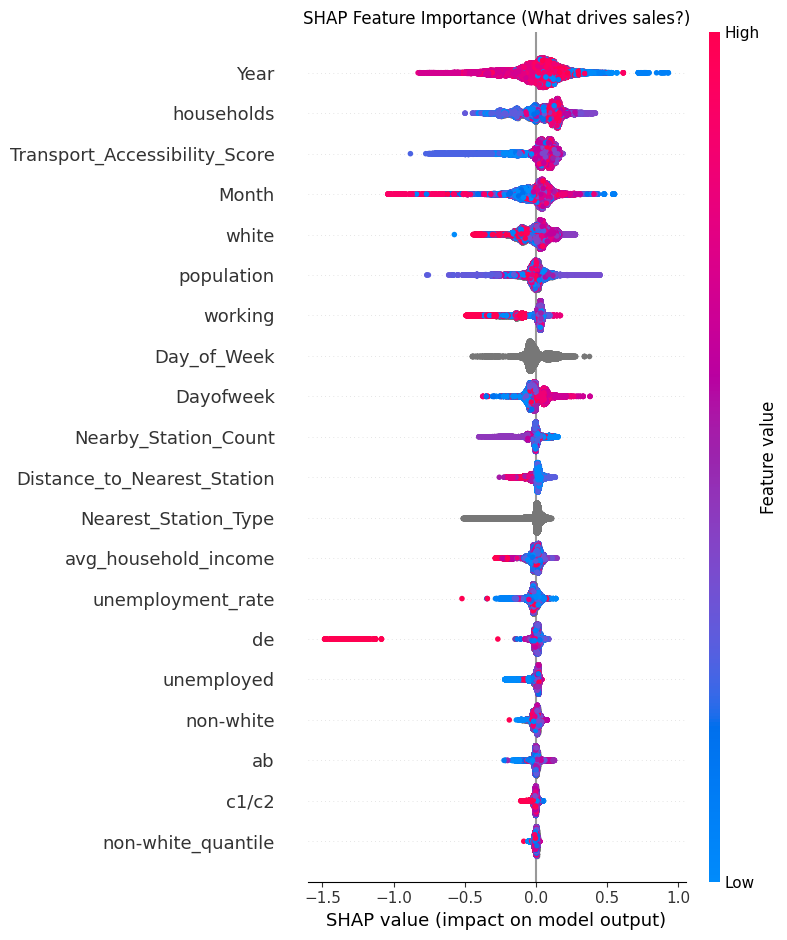

In [ ]:
# 9.1 Global Feature Importance (SHAP Summary Plot)
import shap
import matplotlib.pyplot as plt

# We use the best_xgb model from Section 8
# (If you skipped Section 8, just change best_xgb to xgb_model from Section 7)

print("Calculating SHAP values (this may take a minute)...")
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_train_xgb)

plt.figure(figsize=(10, 8))
plt.title("SHAP Feature Importance (What drives sales?)")
shap.summary_plot(shap_values, X_train_xgb, show=False)
plt.show()


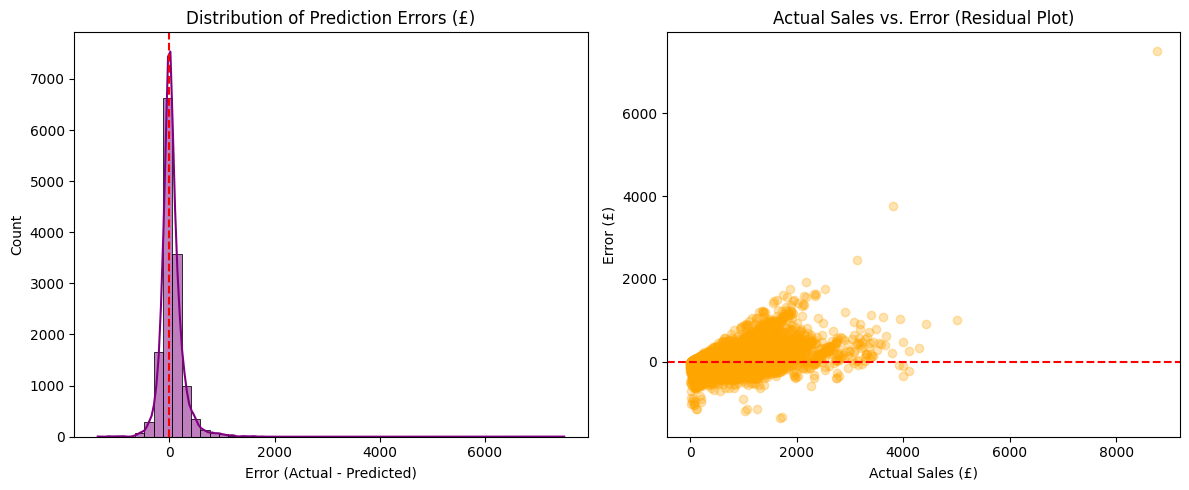

In [ ]:
# 9.2 Error Distribution Analysis
import seaborn as sns
import numpy as np

# Calculate the real £ residual error
best_preds = best_xgb.predict(X_test_xgb)
real_y_test = np.expm1(y_test)
real_best_preds = np.expm1(best_preds)
errors = real_y_test - real_best_preds

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(errors, bins=50, kde=True, color='purple')
plt.title("Distribution of Prediction Errors (£)")
plt.xlabel("Error (Actual - Predicted)")
plt.axvline(x=0, color='r', linestyle='--')

plt.subplot(1, 2, 2)
plt.scatter(real_y_test, errors, alpha=0.3, color='orange')
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Actual Sales vs. Error (Residual Plot)")
plt.xlabel("Actual Sales (£)")
plt.ylabel("Error (£)")

plt.tight_layout()
plt.show()


## 10. Model Export
Finally, we serialize the best XGBoost model and save it to the `models/` directory so our FastAPI application can load it for real-time inference.


In [ ]:
# 10. Final Model & Preprocessor Export (Unified Median Ensemble)
import joblib
import os
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, RegressorMixin

# Safely resolve the absolute path to the root 'models' directory 
# (This goes up one level from 'notebooks' directly into your root 'models')
MODEL_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'models'))
os.makedirs(MODEL_DIR, exist_ok=True)

print(f"Exporting Base Preprocessors to: {MODEL_DIR}...")
joblib.dump(preprocessor, os.path.join(MODEL_DIR, 'preprocessor.pkl'))
joblib.dump(qt, os.path.join(MODEL_DIR, 'quantile_transformer.pkl'))
joblib.dump(kbd, os.path.join(MODEL_DIR, 'kbins_discretizer.pkl'))
joblib.dump(pt, os.path.join(MODEL_DIR, 'power_transformer.pkl'))
joblib.dump(rs, os.path.join(MODEL_DIR, 'robust_scaler.pkl'))
joblib.dump(oe, os.path.join(MODEL_DIR, 'ordinal_encoder.pkl'))
joblib.dump(cols_to_drop, os.path.join(MODEL_DIR, 'cols_to_drop.pkl'))
joblib.dump(categorical_features, os.path.join(MODEL_DIR, 'categorical_features.pkl'))

print("\nConstructing Global Median Ensemble Wrapper...")

class MedianEnsembleRegressor(BaseEstimator, RegressorMixin):
    """
    A custom wrapper class holding XGBoost, LightGBM, CatBoost, and Random Forest.
    It takes a raw Pandas DataFrame, handles the specific categoric typing required 
    by each underlying model, predicts in Log-Space across all 4, and returns the Median Log-Space prediction.
    """
    def __init__(self, xgb_model, lgb_model, cb_model, rf_model, rf_preprocessor, cat_features):
        self.xgb_model = xgb_model
        self.lgb_model = lgb_model
        self.cb_model = cb_model
        self.rf_model = rf_model
        self.rf_preprocessor = rf_preprocessor
        self.cat_features = cat_features
        
    def fit(self, X, y=None):
        pass
        
    def predict(self, X):
        # 1. Random Forest Preprocessing (Scikit-Learn OneHot)
        X_rf = self.rf_preprocessor.transform(X)
        preds_rf = self.rf_model.predict(X_rf)
        
        # 2. XGBoost and LightGBM Preprocessing (Pandas Category Type)
        X_xgb_lgb = X.copy()
        for col in self.cat_features:
            if col in X_xgb_lgb.columns:
                X_xgb_lgb[col] = X_xgb_lgb[col].astype('category')
                
        preds_xgb = self.xgb_model.predict(X_xgb_lgb)
        preds_lgb = self.lgb_model.predict(X_xgb_lgb)
        
        # 3. CatBoost Preprocessing (Explicit String)
        X_cb = X.copy()
        for col in self.cat_features:
            if col in X_cb.columns:
                X_cb[col] = X_cb[col].fillna('Unknown').astype(str)
                
        preds_cb = self.cb_model.predict(X_cb)
        
        # Stack all 4 predictions and calculate the Median across the columns (axis=0)
        all_preds = np.vstack([preds_rf, preds_xgb, preds_lgb, preds_cb])
        median_preds = np.median(all_preds, axis=0)
        
        return median_preds

# Lock in the 'best' tuned models if they exist, otherwise fallback to baseline
active_xgb = best_xgb if 'best_xgb' in globals() else xgb_model
active_lgb = best_lgb if 'best_lgb' in globals() else lgb_model
active_cb = best_cb if 'best_cb' in globals() else cb_model

ensemble_model = MedianEnsembleRegressor(
    xgb_model=active_xgb,
    lgb_model=active_lgb,
    cb_model=active_cb,
    rf_model=rf_model,
    rf_preprocessor=preprocessor,
    cat_features=['Day_of_Week', 'Nearest_Station_Type']
)

print("\nExporting Single Unified Ensemble Model...")
ensemble_path = os.path.join(MODEL_DIR, 'median_ensemble.pkl')
joblib.dump(ensemble_model, ensemble_path)

print(f"✅ Pipeline exported successfully! You now have a unified ensemble at:\n{ensemble_path}")


Exporting Base Preprocessors to: d:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\models...

Constructing Global Median Ensemble Wrapper...

Exporting Single Unified Ensemble Model...
✅ Pipeline exported successfully! You now have a unified ensemble at:
d:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\models\median_ensemble.pkl


In [ ]:
# 10.2 Save the Prediction Dataset for Inference Testing
# We save the prepared 'unseen' data so we can test the API later
PRED_DATA_PATH = r"D:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\data\processed\prediction_features.csv"
X_pred.to_csv(PRED_DATA_PATH, index=False)
print(f"✅ Successfully saved prepared Prediction features to: {PRED_DATA_PATH}")


✅ Successfully saved prepared Prediction features to: D:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\data\processed\prediction_features.csv


In [ ]:
## 11. Run Final Inference on "Prediction" Dataset
import pandas as pd
import numpy as np

print("Generating predictions from all 4 Models (using Bayesian Tuned versions)...")

# 1. Prepare data for each model type
X_pred_rf = preprocessor.transform(X_pred)

X_pred_xgb_lgb = X_pred.copy()
cat_features = ['Day_of_Week', 'Nearest_Station_Type']
for col in cat_features:
    if col in X_pred_xgb_lgb.columns:
        X_pred_xgb_lgb[col] = X_pred_xgb_lgb[col].astype('category')

X_pred_cb = X_pred.copy()
for col in cat_features:
    if col in X_pred_cb.columns:
        X_pred_cb[col] = X_pred_cb[col].fillna('Unknown').astype(str)

# 2. Make Log-Space predictions
print("Predicting with Random Forest (Untuned Baseline)...")
preds_log_rf = rf_model.predict(X_pred_rf)

print("Predicting with Tuned XGBoost...")
active_xgb = best_xgb if 'best_xgb' in globals() else xgb_model
preds_log_xgb = active_xgb.predict(X_pred_xgb_lgb)

print("Predicting with Tuned LightGBM...")
active_lgb = best_lgb if 'best_lgb' in globals() else lgb_model
preds_log_lgb = active_lgb.predict(X_pred_xgb_lgb)

print("Predicting with Tuned CatBoost...")
active_cb = best_cb if 'best_cb' in globals() else cb_model
preds_log_cb = active_cb.predict(X_pred_cb)

# 3. Transform out of Log-Space into real £ Sales
sales_rf = np.expm1(preds_log_rf)
sales_xgb = np.expm1(preds_log_xgb)
sales_lgb = np.expm1(preds_log_lgb)
sales_cb = np.expm1(preds_log_cb)

# 4. Attach predictions to the final dataframe
final_results = df_pred[['Branch Name', 'Date', 'Total Sale']].copy()

final_results['Pred: XGBoost'] = sales_xgb
final_results['Pred: LightGBM'] = sales_lgb
final_results['Pred: CatBoost'] = sales_cb
final_results['Pred: Random Forest'] = sales_rf

def format_actual(val):
    if pd.isna(val) or val == "Unknown":
        return "Unknown"
    return f"£{float(val):,.2f}"

final_results['Total Sale'] = final_results['Total Sale'].apply(format_actual)

models = ['XGBoost', 'LightGBM', 'CatBoost', 'Random Forest']
for model in models:
    col_name = f'Pred: {model}'
    error_col = f'Error: {model}'
    
    final_results[error_col] = final_results.apply(
         lambda row: f"£{(float(row['Total Sale'].replace('£','').replace(',','')) - float(row[col_name])):,.2f}"
         if row['Total Sale'] != "Unknown" else "N/A", axis=1
    )
    final_results[col_name] = final_results[col_name].apply(lambda x: f"£{x:,.2f}")

print("\n🚀 Final Inference Results (Multi-Model Tuned Comparison) 🚀")
display(final_results.head(20))

Generating predictions from all 4 Models (using Bayesian Tuned versions)...
Predicting with Random Forest (Untuned Baseline)...
Predicting with Tuned XGBoost...
Predicting with Tuned LightGBM...
Predicting with Tuned CatBoost...


[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished



🚀 Final Inference Results (Multi-Model Tuned Comparison) 🚀


,Branch Name,Date,Total Sale,Pred: XGBoost,Pred: LightGBM,Pred: CatBoost,Pred: Random Forest,Error: XGBoost,Error: LightGBM,Error: CatBoost,Error: Random Forest
69228,Main,2025-08-02,£272.27,£713.66,£605.59,£572.67,£736.03,£-441.39,£-333.32,£-300.40,£-463.76
69229,Main,2025-08-03,£265.33,£591.55,£613.02,£570.10,£526.29,£-326.22,£-347.69,£-304.77,£-260.96
69230,Main,2025-08-04,£257.74,£547.51,£727.91,£577.00,£544.10,£-289.77,£-470.17,£-319.26,£-286.36
69231,Main,2025-08-05,£276.75,£565.04,£647.98,£551.71,£519.11,£-288.29,£-371.23,£-274.96,£-242.36
69232,Main,2025-08-06,£266.24,£573.86,£751.11,£638.84,£500.68,£-307.62,£-484.87,£-372.60,£-234.44
69233,Main,2025-08-07,£209.12,£615.66,£537.70,£618.53,£502.89,£-406.54,£-328.58,£-409.41,£-293.77
69234,Main,2025-08-08,£448.90,£685.64,£663.78,£626.22,£717.58,£-236.74,£-214.88,£-177.32,£-268.68
69235,Main,2025-08-09,£419.44,£713.66,£605.59,£572.67,£736.03,£-294.22,£-186.15,£-153.23,£-316.59
69236,Main,2025-08-10,£254.06,£591.55,£613.02,£570.10,£526.29,£-337.49,£-358.96,£-316.04,£-272.23
69237,Main,2025-08-11,£152.94,£547.51,£727.91,£577.00,£544.10,£-394.57,£-574.97,£-424.06,£-391.16


## 12. Export Feature Engineering Transformers
For our API to predict sales on raw data, it must apply the exact same mathematical scaling we fitted during training (e.g., the same RobustScaler IQR boundaries). Here we save all stateful Scikit-Learn transformers to disk.


In [ ]:
import joblib
import os

MODEL_DIR = r"D:\work\automation\free_map_tools\final\Location_analyzer\location_analyzer_v2\models"
os.makedirs(MODEL_DIR, exist_ok=True)

export_dict = {
    'quantile_transformer.pkl': 'qt',
    'kbins_discretizer.pkl': 'kbd',
    'power_transformer.pkl': 'pt',
    'robust_scaler.pkl': 'rs',
    'ordinal_encoder.pkl': 'oe',
    'sklearn_preprocessor.pkl': 'preprocessor'
}

exported_count = 0
for filename, var_name in export_dict.items():
    if var_name in globals():
        joblib.dump(globals()[var_name], os.path.join(MODEL_DIR, filename))
        print(f"✅ Exported {var_name} -> {filename}")
        exported_count += 1
    else:
        print(f"⚠️ Skipping {var_name} (not found in memory)")

if exported_count > 0:
    print(f"\n✅ Successfully exported {exported_count} Scikit-Learn transformers to the models/ directory.")
else:
    print(f"\n⚠️ Error: No transformers were found in memory. Please run Section 5 and Section 7 first!")


✅ Exported qt -> quantile_transformer.pkl
✅ Exported kbd -> kbins_discretizer.pkl
✅ Exported pt -> power_transformer.pkl
✅ Exported rs -> robust_scaler.pkl
✅ Exported oe -> ordinal_encoder.pkl
✅ Exported preprocessor -> sklearn_preprocessor.pkl

✅ Successfully exported 6 Scikit-Learn transformers to the models/ directory.


In [ ]:
## 12. 12-Month Time Series Model Error Analysis (DataFrame)

import pandas as pd
import numpy as np

print("Preparing 12-month historical data for time-series extraction...")

# 1. We need a branch with a long history to extract 12 months. 
top_branch = df_hist['Branch Name'].value_counts().idxmax()
print(f"Selected Historical Branch: '{top_branch}'")

branch_data = df_hist[df_hist['Branch Name'] == top_branch].copy()

# Sort by Date
branch_data = branch_data.sort_values('Date')
max_date = branch_data['Date'].max()
min_date = max_date - pd.DateOffset(months=12)

# Filter the last 12 months
branch_data = branch_data[branch_data['Date'] >= min_date].copy()
print(f"Aggregating data from {min_date.date()} to {max_date.date()}")

# 2. Prepare features for prediction
X_hist = branch_data.drop(columns=[c for c in cols_to_drop if c in branch_data.columns])

# Preprocess for Random Forest
X_hist_rf = preprocessor.transform(X_hist)

# Preprocess for XGBoost and LightGBM
X_hist_xgb_lgb = X_hist.copy()
cat_features = ['Day_of_Week', 'Nearest_Station_Type']
for col in cat_features:
    if col in X_hist_xgb_lgb.columns:
        X_hist_xgb_lgb[col] = X_hist_xgb_lgb[col].astype('category')

# Preprocess for CatBoost
X_hist_cb = X_hist.copy()
for col in cat_features:
    if col in X_hist_cb.columns:
        X_hist_cb[col] = X_hist_cb[col].fillna('Unknown').astype(str)

# 3. Predict & Exponentiate (Remove Log space)
branch_data['Pred_RF'] = np.expm1(rf_model.predict(X_hist_rf))

active_xgb = best_xgb if 'best_xgb' in globals() else xgb_model
branch_data['Pred_XGB'] = np.expm1(active_xgb.predict(X_hist_xgb_lgb))

active_lgb = best_lgb if 'best_lgb' in globals() else lgb_model
branch_data['Pred_LGB'] = np.expm1(active_lgb.predict(X_hist_xgb_lgb))

active_cb = best_cb if 'best_cb' in globals() else cb_model
branch_data['Pred_CB'] = np.expm1(active_cb.predict(X_hist_cb))

# 4. Aggregate by Week
branch_data.set_index('Date', inplace=True)
weekly_data = branch_data[['Total Sale', 'Pred_XGB', 'Pred_LGB', 'Pred_CB', 'Pred_RF']].resample('W').sum()

# Drop missing weeks
weekly_data = weekly_data[weekly_data['Total Sale'] > 0]

# Calculate Errors: Actual - Predicted 
weekly_data['Err_XGB'] = weekly_data['Total Sale'] - weekly_data['Pred_XGB']
weekly_data['Err_LGB'] = weekly_data['Total Sale'] - weekly_data['Pred_LGB']
weekly_data['Err_CB'] = weekly_data['Total Sale'] - weekly_data['Pred_CB']
weekly_data['Err_RF'] = weekly_data['Total Sale'] - weekly_data['Pred_RF']

# 5. Output DataFrame
display_data = weekly_data.copy()
for col in display_data.columns:
    display_data[col] = display_data[col].apply(lambda x: f"£{x:,.2f}")

print("\n📊 12-Month Weekly Sales & Model Errors DataFrame 📊")
from IPython.display import display
display(display_data)

# 6. Display Summary Stats
print("\n📈 12-Month Aggregated Weekly Error Summary 📈")
mae_summary = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'CatBoost', 'Random Forest'],
    'Weekly Mean Absolute Error (£)': [
        weekly_data['Err_XGB'].abs().mean(),
        weekly_data['Err_LGB'].abs().mean(),
        weekly_data['Err_CB'].abs().mean(),
        weekly_data['Err_RF'].abs().mean()
    ]
})
mae_summary['Weekly Mean Absolute Error (£)'] = mae_summary['Weekly Mean Absolute Error (£)'].apply(lambda x: f"£{x:,.2f}")
display(mae_summary.sort_values('Weekly Mean Absolute Error (£)'))

# Save to CSV so you can use it in other plotting tools if needed
csv_path = "data/output/weekly_model_predictions.csv"
import os
os.makedirs("data/output", exist_ok=True)
weekly_data.to_csv(csv_path)
print(f"\n✅ Raw numerical data saved to {csv_path} for your own personal graph generation!")

Preparing 12-month historical data for time-series extraction...
Selected Historical Branch: 'rio's piri piri coventry'
Aggregating data from 2024-01-31 to 2025-01-31

📊 12-Month Weekly Sales & Model Errors DataFrame 📊


[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=20)]: Done 100 out of 100 | elapsed:    0.0s finished


,Total Sale,Pred_XGB,Pred_LGB,Pred_CB,Pred_RF,Err_XGB,Err_LGB,Err_CB,Err_RF
Date,,,,,,,,,
2024-02-04,"£28,478.94","£24,995.02","£25,983.00","£26,673.09","£27,098.77","£3,483.92","£2,495.94","£1,805.85","£1,380.17"
2024-02-11,"£35,632.48","£33,552.95","£34,593.40","£35,771.06","£36,094.99","£2,079.53","£1,039.08",£-138.58,£-462.51
2024-02-18,"£35,359.84","£33,552.95","£34,593.40","£35,771.06","£36,094.99","£1,806.89",£766.44,£-411.22,£-735.15
2024-02-25,"£36,221.16","£33,552.95","£34,593.40","£35,771.06","£36,094.99","£2,668.21","£1,627.76",£450.10,£126.17
2024-03-03,"£36,500.62","£32,712.97","£32,603.42","£33,510.87","£33,393.51","£3,787.65","£3,897.20","£2,989.75","£3,107.11"
2024-03-10,"£35,690.98","£31,475.88","£30,286.65","£30,703.48","£31,380.69","£4,215.10","£5,404.33","£4,987.50","£4,310.29"
2024-03-17,"£28,722.84","£31,475.88","£30,286.65","£30,703.48","£31,380.69","£-2,753.04","£-1,563.81","£-1,980.64","£-2,657.85"
2024-03-24,"£30,683.38","£31,475.88","£30,286.65","£30,703.48","£31,380.69",£-792.50,£396.73,£-20.10,£-697.31
2024-03-31,"£31,025.14","£31,475.88","£30,286.65","£30,703.48","£31,380.69",£-450.74,£738.49,£321.66,£-355.55



📈 12-Month Aggregated Weekly Error Summary 📈


,Model,Weekly Mean Absolute Error (£)
3,Random Forest,"£1,525.11"
2,CatBoost,"£1,585.66"
1,LightGBM,"£1,723.35"
0,XGBoost,"£2,257.37"



✅ Raw numerical data saved to data/output/weekly_model_predictions.csv for your own personal graph generation!
